# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [2]:
# 1. Define root path
data_dir = Path("UCI HAR Dataset")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# 2. Check if dataset exists; if not, provide instructions or auto-download
if not data_dir.exists():
    print(f"Dataset folder '{data_dir}' not found locally.")
    print("Attempting to automatically download the UCI HAR dataset...")
    
    try:
        zip_path = Path("uci_har.zip")
        urllib.request.urlretrieve(dataset_url, zip_path)
        
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        # The UCI zip contains a nested zip or folder structure sometimes, 
        # let's clean up the zip file
        zip_path.unlink()
        print("Dataset downloaded and extracted successfully!")
        
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"Extract the 'UCI HAR Dataset' folder into your project root directory."
        )

# 3. Load features safely
features_file = data_dir / "features.txt"
if not features_file.exists():
    raise FileNotFoundError(f"Required file missing: {features_file}. Check your folder structure.")

features_df = pd.read_csv(features_file, sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Successfully loaded 561 unique feature names.


### Split Dataset

In [3]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
data_dir = Path("UCI HAR Dataset")

features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 563)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 563)

Train shape: (7352, 563)
Test shape:  (2947, 563)


## Dataset Preprocessing

### Missingness Analysis

In [4]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0


Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 563)
Test shape:  (2947, 563)


Retrieve Feature Columns

### Apply standard scaling

Retain both the scaled and unscaled version

In [5]:
train_df

,subject_id,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7347,30,2,0.299665,-0.057193,-0.181233,-0.195387,0.039905,0.077078,-0.282301,0.043616,...,-0.070157,-0.588433,-0.880324,-0.190437,0.829718,0.206972,-0.425619,-0.791883,0.238604,0.049819
7348,30,2,0.273853,-0.007749,-0.147468,-0.235309,0.004816,0.059280,-0.322552,-0.029456,...,0.165259,-0.390738,-0.680744,0.064907,0.875679,-0.879033,0.400219,-0.771840,0.252676,0.050053
7349,30,2,0.273387,-0.017011,-0.045022,-0.218218,-0.103822,0.274533,-0.304515,-0.098913,...,0.195034,0.025145,-0.304029,0.052806,-0.266724,0.864404,0.701169,-0.779133,0.249145,0.040811
7350,30,2,0.289654,-0.018843,-0.158281,-0.219139,-0.111412,0.268893,-0.310487,-0.068200,...,0.013865,0.063907,-0.344314,-0.101360,0.700740,0.936674,-0.589479,-0.785181,0.246432,0.025339


In [6]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate features from metadata
meta_cols = ["subject_id", "activity_id"]

X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)

# Preserve metadata separately
meta_train = train_df[meta_cols].copy()
# Preserve metadata separately for test
meta_test = test_df[meta_cols].copy()

# Initialize the scaler
scaler = StandardScaler()

# Fit on the training features and transform both train and test sets
# (Fitting strictly on train to prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve original 561 feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Scaled Training Shape: {X_train_scaled_df.shape}")
print(f"Scaled Testing Shape:  {X_test_scaled_df.shape}")

Scaled Training Shape: (7352, 561)
Scaled Testing Shape:  (2947, 561)


### Items to use for EDA

In [7]:
print(f"Unscaled Dataset: ", X_train.shape)
print(f"Scaled dataset: ", X_train_scaled.shape)
print(f"Subject and Activity ID for training set: ", meta_train.shape)
print(f"Subject and Activity ID for test set: ", meta_test.shape)

Unscaled Dataset:  (7352, 561)
Scaled dataset:  (7352, 561)
Subject and Activity ID for training set:  (7352, 2)
Subject and Activity ID for test set:  (2947, 2)


### Exploratory Data Analysis

Task 1 — Data quality and feature characteristics
Objective: Understand the quality and structure of the sensor measurements.

**Member**: Atharva

What needs to be done:

1. Check missing values, duplicates, constant features and extreme values.
2. Examine feature distributions and variance.
3. Identify highly correlated and redundant features.
4. Group features by their physical meaning: acceleration, gyroscope, gravity, jerk, time-domain and frequency-domain.
5. Examine how standardisation and duplicate-feature removal change feature distributions and relative weighting.

Expected output: A summary of data quality, feature redundancy and recommended preprocessing decisions.

In [8]:
# Code for EDA 1

Task 2 — Natural structure and movement relationships

Objective: Investigate whether the sensor data suggest meaningful movement groups and relationships.

**Member**: Abrar

What needs to be done:
1. Explore PCA projections of the sensor measurements.
2. Examine whether observations form distinct regions, overlapping distributions or continuous patterns.
3. Look for broad movement families and possible finer subdivisions.
4. Compare the apparent structure against known activity labels, using labels only for interpretation.
5. Investigate whether some activities occupy overlapping or nested regions of sensor space.
Expected output: Evidence describing the apparent organisation of movement and hypotheses about shared movement patterns.

At this stage, visual groupings are exploratory evidence, not validated clusters.


In [9]:
# Code for EDA 2


Task 3 — Physical interpretation of movement patterns
Objective: Understand which sensor characteristics distinguish or connect different movement patterns.

**Member**: Youssef

What needs to be done:
1. Explore acceleration, gyroscope and gravity-related feature distributions.
2. Compare time-domain and frequency-domain characteristics.
3. Identify which physical features differ most between activity groups.
4. Examine which activities share similar physical characteristics.
5. Investigate whether movement differences are associated with motion intensity, periodicity or orientation.
Expected output: Interpretable physical explanations for similarities and differences between movement patterns.



In [10]:
# Code for EDA 3

Task 4 — Movement variability and diversity
Objective: Determine whether some types of movement exhibit greater internal variation than others.

What needs to be done:
1. Compare within-activity feature variance and multivariate dispersion.
2. Examine local neighbourhood distances and density differences.
3. Investigate whether some activities contain several distinct movement patterns.
4. Determine whether activity variability is distributed across participants or concentrated in a few individuals.
5. Investigate why walking downstairs is disproportionately represented among the existing high-scoring unusual observations.
Expected output: Evidence identifying which movements are more heterogeneous and potential explanations for their apparent unusualness.

In [11]:
# Code for EDA 5

Task 5 — Participant-specific movement characteristics
Objective: Investigate whether individuals exhibit consistent and distinguishable movement patterns.

**Member**: Sushanth

What needs to be done:
1. Compare participants while controlling for activity type.
2. Examine how participant-specific feature distributions differ.
3. Investigate whether some participants occupy distinct regions within the same activity.
4. Compare within-participant and between-participant variability.
5. Examine whether participant 19 is consistently distinctive or whether only a few observations are extreme.
Expected output: Evidence showing whether individual movement differences are systematic or concentrated in isolated observations.


In [12]:
# Code for EDA 5

Task 6 — Preliminary anomaly characteristics and concentration
Objective: Investigate which observations appear unusual and whether they are isolated or associated with recurring patterns.

**Member**: Muhatasim

What needs to be done:
1. Reproduce baseline neighbourhood-distance anomaly scores.
2. Examine score distributions and identify high-scoring observations for inspection.
3. Analyse anomaly concentration across activities and participants, accounting for their different sample sizes.
4. Determine whether high-scoring observations have other similar unusual observations nearby.
5. Inspect selected raw inertial-signal windows to identify distinguishing signal characteristics.
6. Compare preliminary unusualness under global neighbourhoods and restricted neighbourhoods, without treating either as ground truth.
Expected output: A preliminary anomaly profile identifying the observations and patterns that warrant further investigation.

#### 6.0 Setup
Shared objects for Task 6 and RQ3: activity names, raw inertial windows, and a per-window table with each window's position inside its continuous recording segment. Windows are 2.56 s at 50 Hz with 50% overlap, stored in time order, so a new segment starts when subject/activity changes or the 64-sample overlap breaks.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

activity_labels = pd.read_csv(data_dir / "activity_labels.txt", sep=r"\s+", header=None,
                              names=["activity_id", "activity_name"])
ACTIVITY_NAMES = dict(zip(activity_labels["activity_id"], activity_labels["activity_name"]))
ACTIVITY_ORDER = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]

K = 15        # neighbourhood size for the baseline k-NN distance score
TOP_PCT = 95  # windows above this percentile form the inspection shortlist (not ground-truth anomalies)
SIGNALS = ["body_acc", "body_gyro", "total_acc"]


def load_inertial(split):
    """Raw 50 Hz inertial windows (n_windows x 128) for each signal and axis."""
    folder = data_dir / split / "Inertial Signals"
    return {f"{s}_{a}": pd.read_csv(folder / f"{s}_{a}_{split}.txt", sep=r"\s+", header=None).to_numpy()
            for s in SIGNALS for a in "xyz"}


def add_window_meta(meta, split, inertial):
    """One row per window: ids, activity name and position inside its continuous recording segment."""
    df = meta.reset_index(drop=True).copy()
    df["split"] = split
    df["row"] = np.arange(len(df))                      # row position in train_df / test_df
    df["activity_name"] = df["activity_id"].map(ACTIVITY_NAMES)
    sig = inertial["body_acc_x"]
    overlaps = np.r_[False, np.isclose(sig[:-1, 64:], sig[1:, :64], atol=1e-6).all(axis=1)]
    same_group = (df["subject_id"].eq(df["subject_id"].shift())
                  & df["activity_id"].eq(df["activity_id"].shift()))
    df["segment_id"] = (~(same_group & overlaps)).cumsum() - 1
    df["pos_in_segment"] = df.groupby("segment_id").cumcount()
    return df


inertial_train = load_inertial("train")
inertial_test = load_inertial("test")
WINDOW_TABLE = {"train": add_window_meta(meta_train, "train", inertial_train),
                "test": add_window_meta(meta_test, "test", inertial_test)}

t6 = WINDOW_TABLE["train"].copy()   # Task 6 uses the training split (21 of the 30 participants)
print(f"Train: {len(t6)} windows, {t6['subject_id'].nunique()} participants, "
      f"{t6['segment_id'].nunique()} continuous recording segments")

Train: 7352 windows, 21 participants, 600 continuous recording segments


#### 6.1 Baseline neighbourhood-distance anomaly score
Score = Euclidean distance to the K-th nearest neighbour in the standardised 561-feature space. High-scoring = above the 95th percentile.

In [14]:
nn_global = NearestNeighbors(n_neighbors=K + 1, metric="euclidean").fit(X_train_scaled)
dist_global, idx_global = nn_global.kneighbors(X_train_scaled)
dist_global, idx_global = dist_global[:, 1:], idx_global[:, 1:]   # drop column 0 (each point itself)

t6["knn_score"] = dist_global[:, -1]
threshold = np.percentile(t6["knn_score"], TOP_PCT)
t6["is_high"] = t6["knn_score"] > threshold
BASE_RATE = t6["is_high"].mean()

print(f"k = {K}; {TOP_PCT}th percentile threshold = {threshold:.2f}")
print(f"High-scoring windows: {t6['is_high'].sum()} / {len(t6)} ({BASE_RATE:.1%})")

k = 15; 95th percentile threshold = 22.92
High-scoring windows: 368 / 7352 (5.0%)


#### 6.2 Score distribution and high-scoring windows

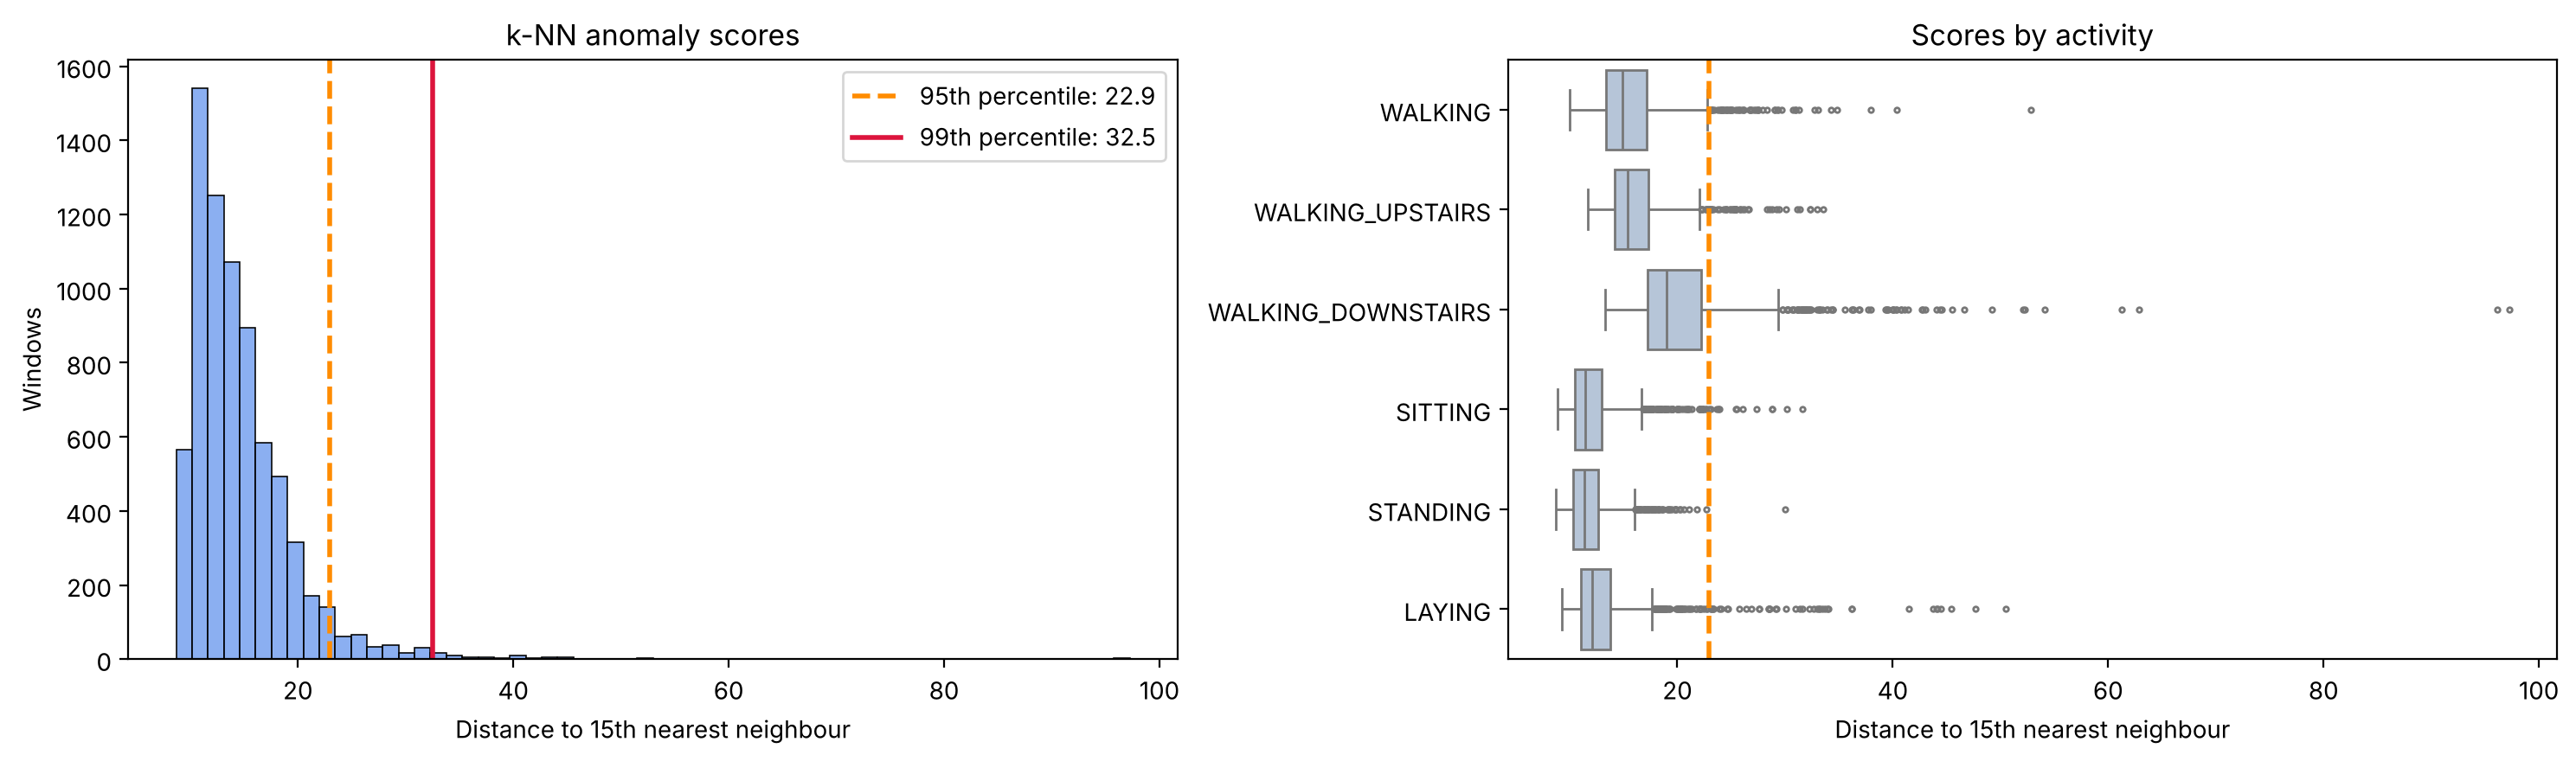

Top 15 windows for inspection:


,row,subject_id,activity_name,segment_id,pos_in_segment,knn_score
3934,3934,19,WALKING_DOWNSTAIRS,340,0,97.246151
3935,3935,19,WALKING_DOWNSTAIRS,340,1,96.170270
3939,3939,19,WALKING_DOWNSTAIRS,340,5,62.882818
3936,3936,19,WALKING_DOWNSTAIRS,340,2,61.229543
3928,3928,19,WALKING_DOWNSTAIRS,339,0,54.090222
3915,3915,19,WALKING,337,12,52.789011
3930,3930,19,WALKING_DOWNSTAIRS,339,2,52.221489
3958,3958,19,WALKING_DOWNSTAIRS,343,5,52.066144
2451,2451,14,LAYING,223,0,50.473317
3929,3929,19,WALKING_DOWNSTAIRS,339,1,49.227512


In [15]:
p99 = np.percentile(t6["knn_score"], 99)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(t6["knn_score"], bins=60, color="cornflowerblue", ax=axes[0])
axes[0].axvline(threshold, color="darkorange", ls="--", lw=2, label=f"{TOP_PCT}th percentile: {threshold:.1f}")
axes[0].axvline(p99, color="crimson", lw=2, label=f"99th percentile: {p99:.1f}")
axes[0].set(title="k-NN anomaly scores", xlabel=f"Distance to {K}th nearest neighbour", ylabel="Windows")
axes[0].legend()
sns.boxplot(data=t6, x="knn_score", y="activity_name", order=ACTIVITY_ORDER, color="lightsteelblue",
            fliersize=2, ax=axes[1])
axes[1].axvline(threshold, color="darkorange", ls="--", lw=2)
axes[1].set(title="Scores by activity", xlabel=f"Distance to {K}th nearest neighbour", ylabel="")
plt.tight_layout()
plt.show()

print("Top 15 windows for inspection:")
display(t6.nlargest(15, "knn_score")[["row", "subject_id", "activity_name", "segment_id",
                                      "pos_in_segment", "knn_score"]])

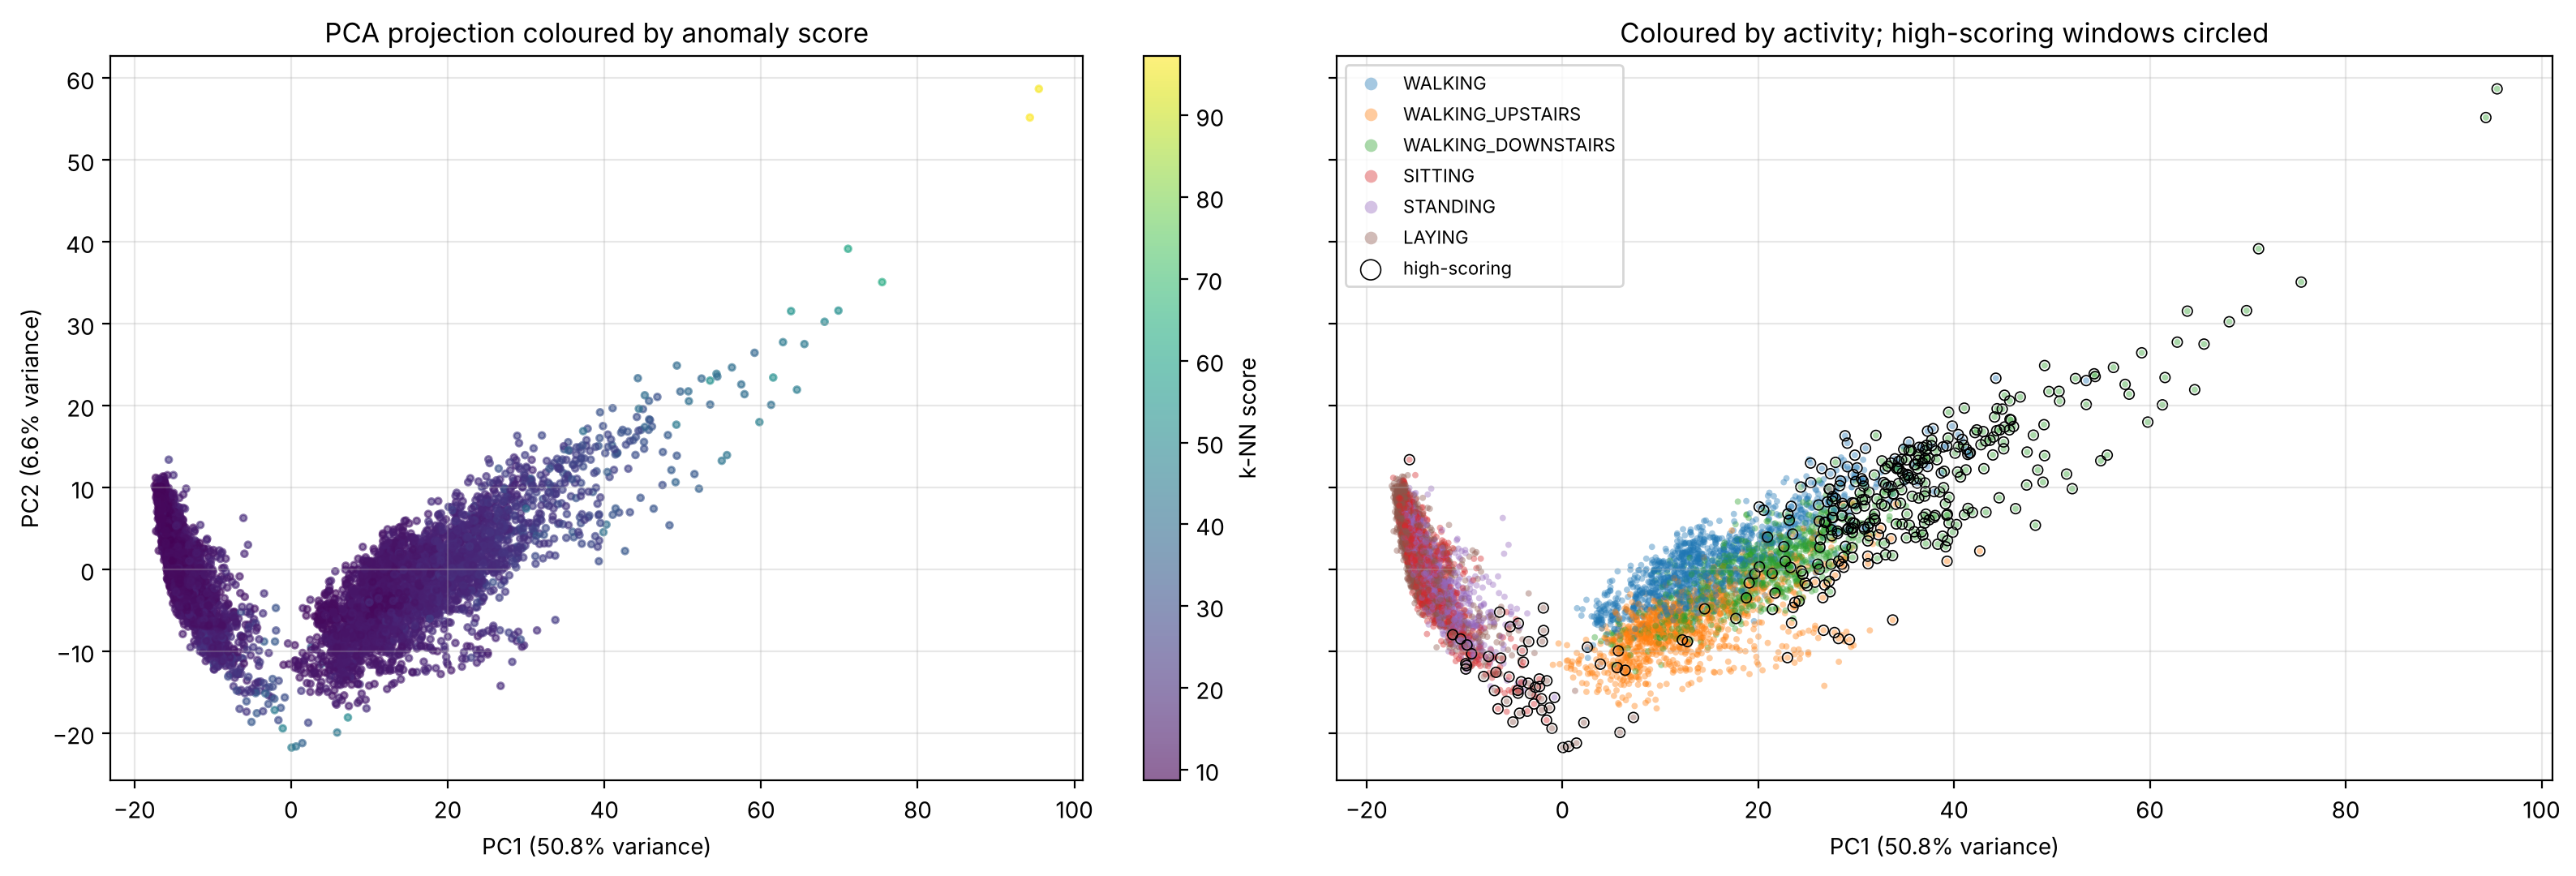

In [16]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_train_scaled)
t6["PC1"], t6["PC2"] = pcs[:, 0], pcs[:, 1]
ev = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True, sharey=True)
sc = axes[0].scatter(t6["PC1"], t6["PC2"], c=t6["knn_score"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, ax=axes[0], label="k-NN score")
axes[0].set_title("PCA projection coloured by anomaly score")
sns.scatterplot(data=t6, x="PC1", y="PC2", hue="activity_name", hue_order=ACTIVITY_ORDER, palette="tab10",
                s=8, alpha=0.4, linewidth=0, ax=axes[1])
high = t6[t6["is_high"]]
axes[1].scatter(high["PC1"], high["PC2"], facecolors="none", edgecolors="black", s=20, linewidths=0.6,
                label="high-scoring")
axes[1].legend(markerscale=2, fontsize=8)
axes[1].set_title("Coloured by activity; high-scoring windows circled")
for ax in axes:
    ax.set(xlabel=f"PC1 ({ev[0]:.1f}% variance)", ylabel=f"PC2 ({ev[1]:.1f}% variance)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 6.3 Concentration across activities and participants
Activities and participants have different numbers of windows, so we compare **rates**, not counts. For participants the expected count uses each window's activity rate, so someone with more walking-downstairs windows is not counted as unusual just for that.

In [17]:
from scipy.stats import binomtest


def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, float)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


act_conc = t6.groupby("activity_name").agg(n=("is_high", "size"), n_high=("is_high", "sum"),
                                           rate=("is_high", "mean"))
act_conc["enrichment"] = act_conc["rate"] / BASE_RATE
act_conc["p_holm"] = holm([binomtest(int(k), int(n), BASE_RATE, alternative="greater").pvalue
                           for k, n in zip(act_conc["n_high"], act_conc["n"])])

t6["activity_rate"] = t6.groupby("activity_id")["is_high"].transform("mean")
subj_conc = t6.groupby("subject_id").agg(n=("is_high", "size"), n_high=("is_high", "sum"),
                                         expected=("activity_rate", "sum"), rate=("is_high", "mean"))
subj_conc["enrichment_adj"] = subj_conc["n_high"] / subj_conc["expected"]
subj_conc["share_of_high"] = subj_conc["n_high"] / subj_conc["n_high"].sum()

display(act_conc.sort_values("enrichment", ascending=False)
        .style.format({"rate": "{:.1%}", "enrichment": "{:.2f}", "p_holm": "{:.2g}"}))
display(subj_conc.sort_values("enrichment_adj", ascending=False).head(8)
        .style.format({"expected": "{:.1f}", "rate": "{:.1%}", "enrichment_adj": "{:.2f}",
                       "share_of_high": "{:.1%}"}))

,n,n_high,rate,enrichment,p_holm
activity_name,,,,,
WALKING_DOWNSTAIRS,986,208,21.1%,4.21,1.3e-68
WALKING,1226,61,5.0%,0.99,1
WALKING_UPSTAIRS,1073,42,3.9%,0.78,1
LAYING,1407,43,3.1%,0.61,1
SITTING,1286,13,1.0%,0.20,1
STANDING,1374,1,0.1%,0.01,1


,n,n_high,expected,rate,enrichment_adj,share_of_high
subject_id,,,,,,
19,360,64,15.7,17.8%,4.07,17.4%
8,281,52,14.2,18.5%,3.67,14.1%
23,372,61,19.3,16.4%,3.17,16.6%
14,323,51,16.7,15.8%,3.06,13.9%
6,325,44,17.3,13.5%,2.54,12.0%
25,409,24,21.4,5.9%,1.12,6.5%
1,347,17,19.2,4.9%,0.89,4.6%
7,308,12,16.9,3.9%,0.71,3.3%


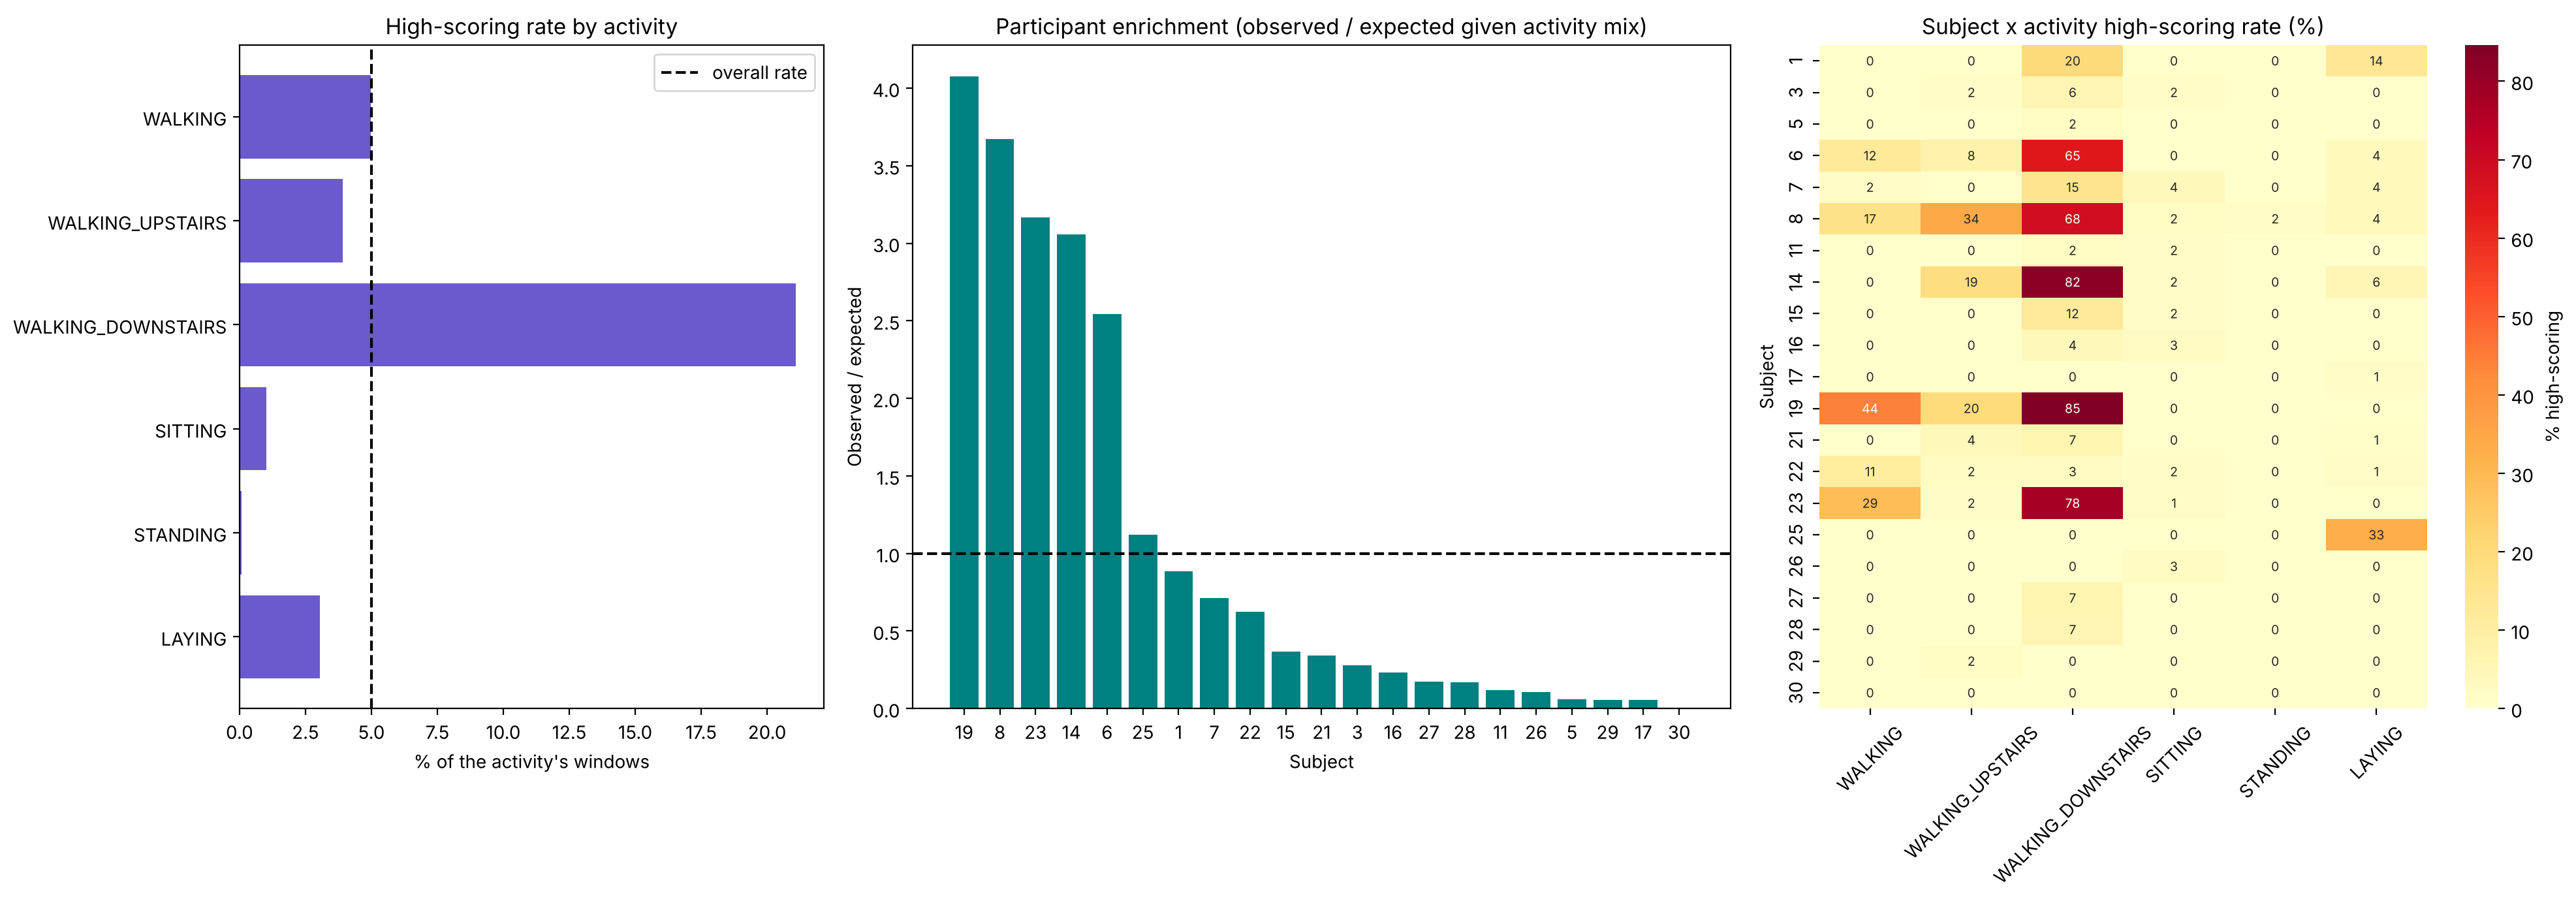

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 1.4, 1.3]})

a = act_conc.reindex(ACTIVITY_ORDER)
axes[0].barh(a.index, a["rate"] * 100, color="slateblue")
axes[0].axvline(BASE_RATE * 100, color="black", ls="--", label="overall rate")
axes[0].invert_yaxis()
axes[0].set(title="High-scoring rate by activity", xlabel="% of the activity's windows")
axes[0].legend()

s = subj_conc.sort_values("enrichment_adj", ascending=False)
axes[1].bar(s.index.astype(str), s["enrichment_adj"], color="teal")
axes[1].axhline(1, color="black", ls="--")
axes[1].set(title="Participant enrichment (observed / expected given activity mix)",
            xlabel="Subject", ylabel="Observed / expected")

rate_mat = t6.pivot_table(index="subject_id", columns="activity_name", values="is_high",
                          aggfunc="mean")[ACTIVITY_ORDER] * 100
sns.heatmap(rate_mat, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% high-scoring"}, ax=axes[2])
axes[2].set(title="Subject x activity high-scoring rate (%)", xlabel="", ylabel="Subject")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

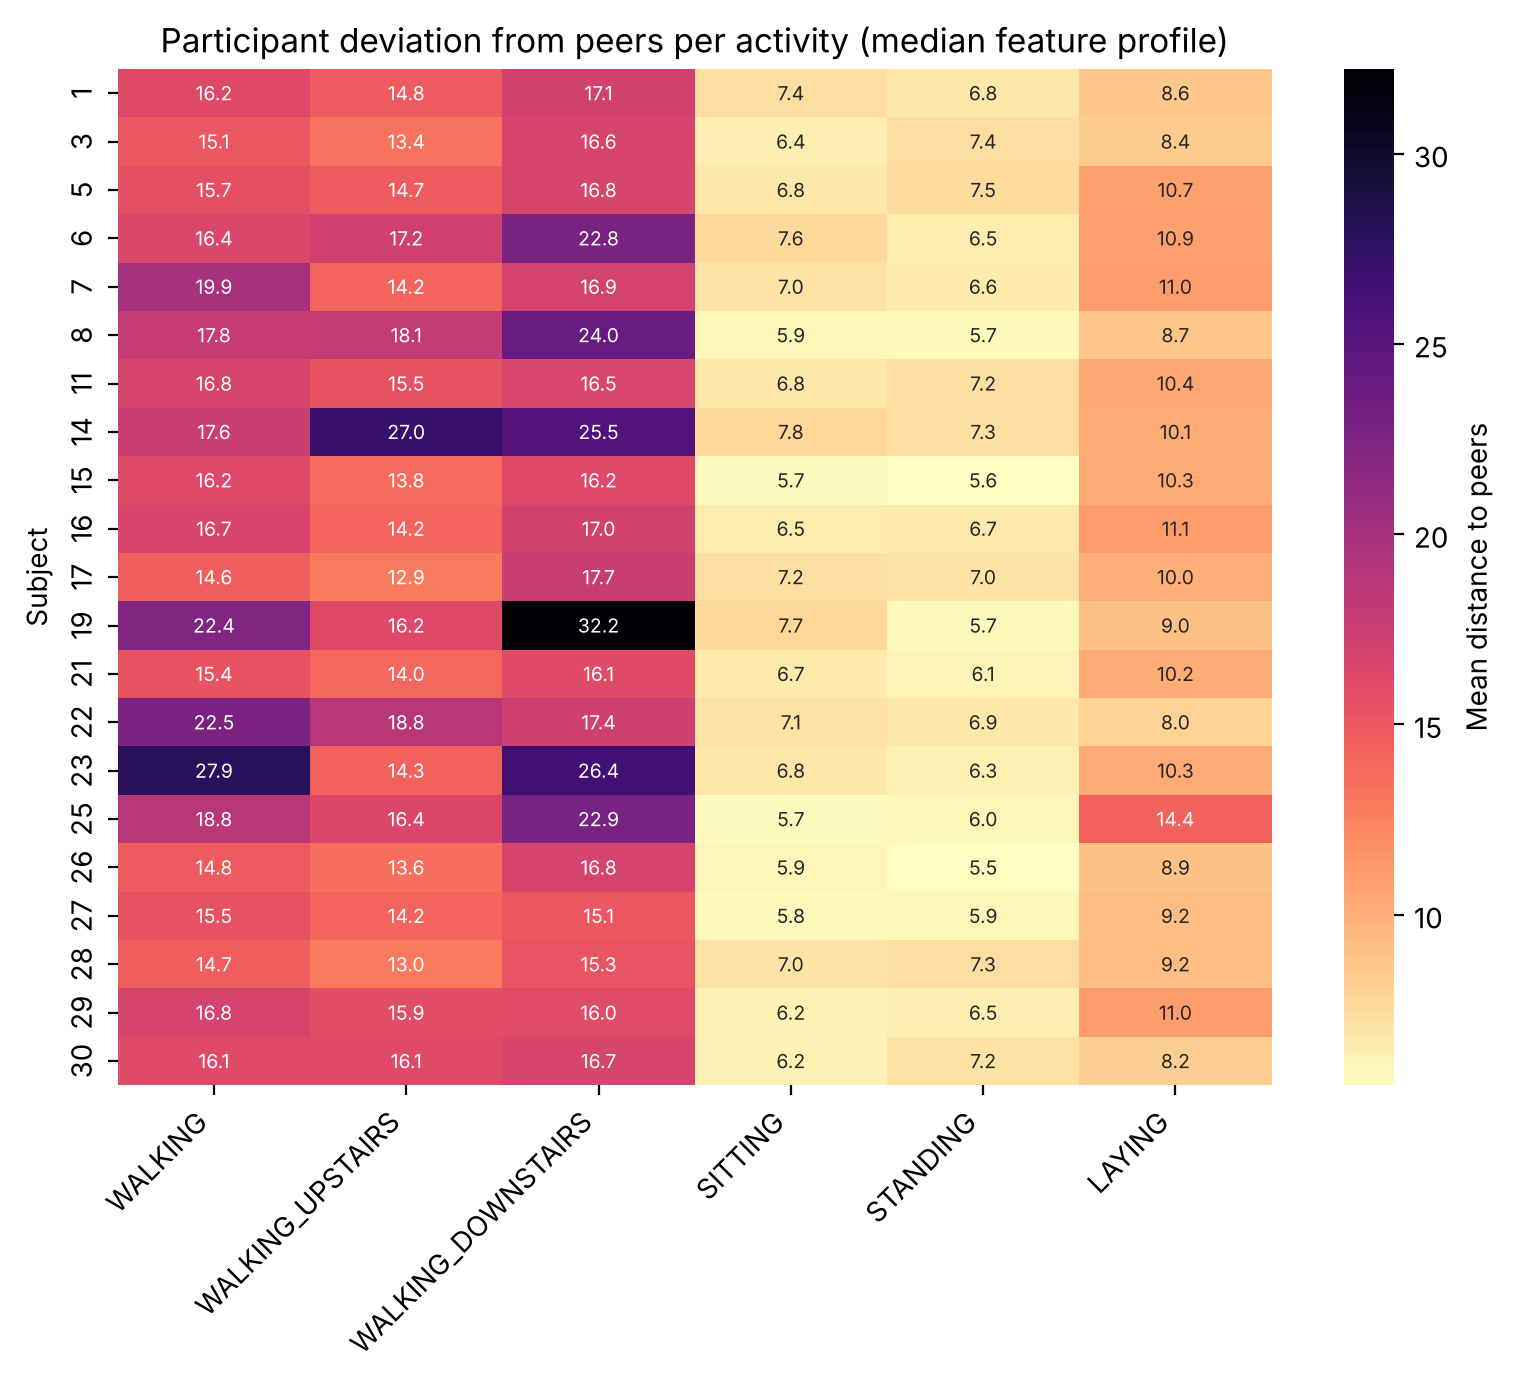

In [19]:
# Participant deviation from peers within each activity (distance between median feature profiles)
from scipy.spatial.distance import cdist

profiles = (pd.DataFrame(X_train_scaled)
            .assign(subject_id=t6["subject_id"].values, activity_name=t6["activity_name"].values)
            .groupby(["activity_name", "subject_id"]).median())
rows = []
for act_name, grp in profiles.groupby(level="activity_name"):
    D = cdist(grp.values, grp.values)
    np.fill_diagonal(D, np.nan)
    rows += [{"activity_name": act_name, "subject_id": s, "mean_distance_to_peers": d}
             for s, d in zip(grp.index.get_level_values("subject_id"), np.nanmean(D, axis=1))]
peer_dev = (pd.DataFrame(rows)
            .pivot(index="subject_id", columns="activity_name", values="mean_distance_to_peers")[ACTIVITY_ORDER])

plt.figure(figsize=(8, 7))
sns.heatmap(peer_dev, cmap="magma_r", annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Mean distance to peers"})
plt.title("Participant deviation from peers per activity (median feature profile)")
plt.xlabel("")
plt.ylabel("Subject")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 6.4 Do high-scoring windows have other unusual windows nearby?
Two kinds of neighbour: the K nearest windows in **feature space** from *other* recording segments (adjacent windows overlap, so same-segment neighbours are trivially similar), and the windows 2 steps before/after in the **same recording** (lag 2, because lag-1 windows share half their samples).

In [20]:
# Adjacent windows of one recording overlap by 50%, so they are each other's nearest neighbours.
# To ask "are there similar unusual windows ELSEWHERE?", take the K nearest windows from OTHER segments.
N_WIDE = 80   # longest segment has 48 windows, so 80 always leaves >= K from other segments
_, idx_wide = nn_global.kneighbors(X_train_scaled, n_neighbors=N_WIDE + 1)
idx_wide = idx_wide[:, 1:]
seg = t6["segment_id"].to_numpy()
other_seg = seg[idx_wide] != seg[:, None]
assert other_seg.sum(axis=1).min() >= K
idx_xseg = np.take_along_axis(idx_wide, np.argsort(~other_seg, axis=1, kind="stable")[:, :K], axis=1)
print(f"Share of the global {K} nearest neighbours that come from the same recording segment: "
      f"{(seg[idx_global] == seg[:, None]).mean():.0%}")

high_flag = t6["is_high"].to_numpy()
subj = t6["subject_id"].to_numpy()
act = t6["activity_id"].to_numpy()
t6["frac_nbrs_high"] = high_flag[idx_xseg].mean(axis=1)
t6["frac_nbrs_same_subject"] = (subj[idx_xseg] == subj[:, None]).mean(axis=1)
t6["frac_nbrs_same_activity"] = (act[idx_xseg] == act[:, None]).mean(axis=1)

seg_len = t6.groupby("segment_id")["row"].transform("size")
t6["at_segment_edge"] = (t6["pos_in_segment"] < 2) | (t6["pos_in_segment"] >= seg_len - 2)

seg_flags = t6.groupby("segment_id")["is_high"]
t6["temporal_nbr_high"] = (seg_flags.shift(2, fill_value=False) | seg_flags.shift(-2, fill_value=False))

t6["nbr_pattern"] = pd.cut(t6["frac_nbrs_high"], [-0.01, 0, 0.2, 1.0],
                           labels=["isolated (0 high nbrs)", "sparse (<=20%)", "grouped (>20%)"])
high = t6[t6["is_high"]]
print(f"High-scoring windows: on average {high['frac_nbrs_high'].mean():.0%} of their {K} nearest windows from other "
      f"segments are also high-scoring (random flags would give {BASE_RATE:.0%}).")
print(f"{high['temporal_nbr_high'].mean():.0%} have a high-scoring window 2 steps away in the same recording "
      f"(vs {t6.loc[~t6['is_high'], 'temporal_nbr_high'].mean():.0%} for other windows).")
print(f"{high['at_segment_edge'].mean():.0%} of high-scoring windows lie within 2 windows of a recording's start/end "
      f"(vs {t6['at_segment_edge'].mean():.0%} of all windows).")

nbr_summary = high.groupby("activity_name").agg(
    n_high=("is_high", "size"),
    isolated=("nbr_pattern", lambda s: (s == "isolated (0 high nbrs)").mean()),
    grouped=("nbr_pattern", lambda s: (s == "grouped (>20%)").mean()),
    nbrs_same_subject=("frac_nbrs_same_subject", "mean"),
    temporal_nbr_high=("temporal_nbr_high", "mean"),
    at_segment_edge=("at_segment_edge", "mean"),
).reindex([a for a in ACTIVITY_ORDER if a in high["activity_name"].unique()])
display(nbr_summary.style.format("{:.0%}", subset=nbr_summary.columns[1:]))

Share of the global 15 nearest neighbours that come from the same recording segment: 22%
High-scoring windows: on average 45% of their 15 nearest windows from other segments are also high-scoring (random flags would give 5%).
61% have a high-scoring window 2 steps away in the same recording (vs 3% for other windows).
52% of high-scoring windows lie within 2 windows of a recording's start/end (vs 33% of all windows).


,n_high,isolated,grouped,nbrs_same_subject,temporal_nbr_high,at_segment_edge
activity_name,,,,,,
WALKING,61,10%,52%,77%,57%,28%
WALKING_UPSTAIRS,42,21%,21%,63%,29%,62%
WALKING_DOWNSTAIRS,208,6%,75%,64%,75%,56%
SITTING,13,31%,54%,3%,0%,85%
STANDING,1,0%,100%,13%,0%,100%
LAYING,43,7%,60%,23%,49%,44%


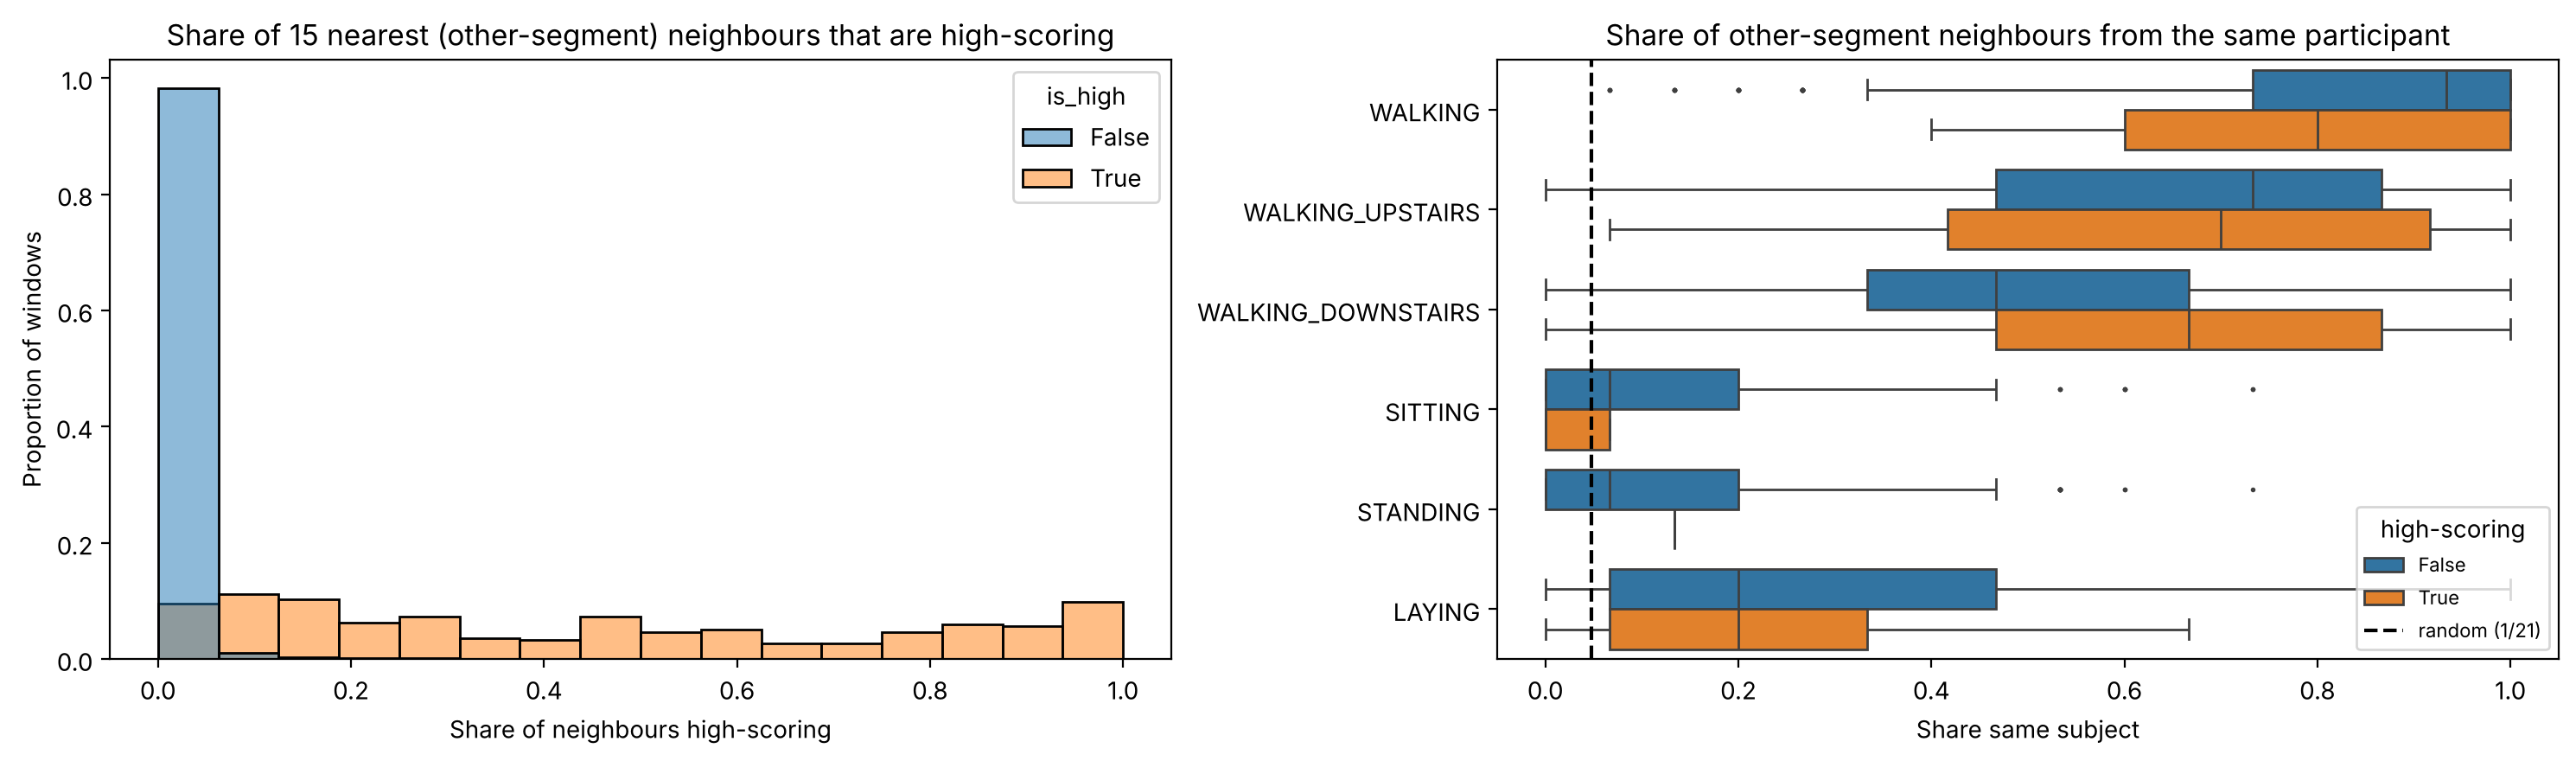

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=t6, x="frac_nbrs_high", hue="is_high", stat="probability", common_norm=False,
             bins=np.linspace(0, 1, K + 2), ax=axes[0])
axes[0].set(title=f"Share of {K} nearest (other-segment) neighbours that are high-scoring",
            xlabel="Share of neighbours high-scoring", ylabel="Proportion of windows")
sns.boxplot(data=t6, x="frac_nbrs_same_subject", y="activity_name", hue="is_high", order=ACTIVITY_ORDER,
            fliersize=1, ax=axes[1])
axes[1].axvline(1 / t6["subject_id"].nunique(), color="black", ls="--", label="random (1/21)")
axes[1].set(title="Share of other-segment neighbours from the same participant", xlabel="Share same subject", ylabel="")
axes[1].legend(title="high-scoring", fontsize=8)
plt.tight_layout()
plt.show()

#### 6.5 Raw inertial-signal characteristics
Simple per-window signal descriptors: intensity (RMS / peak body acceleration, RMS rotation), periodicity (dominant frequency and the share of spectral energy there) and orientation (mean gravity direction). The table shows how far high-scoring windows sit from the other windows of the same activity, in units of that activity's IQR.

In [22]:
FS = 50  # Hz


def magnitude(sig, name):
    return np.sqrt(sig[f"{name}_x"] ** 2 + sig[f"{name}_y"] ** 2 + sig[f"{name}_z"] ** 2)


acc_mag = magnitude(inertial_train, "body_acc")     # g, gravity removed
gyro_mag = magnitude(inertial_train, "body_gyro")   # rad/s
freqs = np.fft.rfftfreq(128, d=1 / FS)
spec = np.abs(np.fft.rfft(acc_mag - acc_mag.mean(axis=1, keepdims=True), axis=1))[:, 1:]

SIG_COLS = ["acc_rms", "acc_peak", "gyro_rms", "dominant_freq_hz", "periodicity",
            "gravity_x", "gravity_y", "gravity_z"]
sig_feats = pd.DataFrame({
    "acc_rms": np.sqrt((acc_mag ** 2).mean(axis=1)),
    "acc_peak": acc_mag.max(axis=1),
    "gyro_rms": np.sqrt((gyro_mag ** 2).mean(axis=1)),
    "dominant_freq_hz": freqs[1:][spec.argmax(axis=1)],
    "periodicity": spec.max(axis=1) / spec.sum(axis=1),
    "gravity_x": inertial_train["total_acc_x"].mean(axis=1),
    "gravity_y": inertial_train["total_acc_y"].mean(axis=1),
    "gravity_z": inertial_train["total_acc_z"].mean(axis=1),
})
t6 = t6.drop(columns=SIG_COLS, errors="ignore").join(sig_feats)


def robust_shift(grp):
    """(median of high-scoring - median of others) / IQR of others, per signal descriptor."""
    hi, lo = grp.loc[grp["is_high"], SIG_COLS], grp.loc[~grp["is_high"], SIG_COLS]
    iqr = (lo.quantile(0.75) - lo.quantile(0.25)).replace(0, np.nan)
    return (hi.median() - lo.median()) / iqr


shift_tbl = (t6.groupby("activity_name")[SIG_COLS + ["is_high"]].apply(robust_shift)
             .reindex(ACTIVITY_ORDER))
shift_tbl["n_high"] = t6.groupby("activity_name")["is_high"].sum().reindex(ACTIVITY_ORDER)
display(shift_tbl.style.format("{:+.2f}", subset=SIG_COLS)
        .background_gradient(cmap="RdBu_r", vmin=-3, vmax=3, subset=SIG_COLS)
        .set_caption("Shift of high-scoring windows vs other windows of the same activity (in IQRs)"))

,acc_rms,acc_peak,gyro_rms,dominant_freq_hz,periodicity,gravity_x,gravity_y,gravity_z,n_high
activity_name,,,,,,,,,
WALKING,+1.59,+1.31,+1.49,+1.00,-0.32,-0.19,+0.18,-0.57,61
WALKING_UPSTAIRS,+1.09,+0.91,+1.57,-0.40,-0.73,-1.07,-0.23,-0.97,42
WALKING_DOWNSTAIRS,+0.75,+1.08,+1.63,-0.60,-0.41,-0.67,-0.39,-0.67,208
SITTING,+20.36,+18.24,+3.64,+0.00,+1.91,-0.11,+0.38,+0.03,13
STANDING,+17.19,+14.90,+5.10,+0.00,+1.88,-1.95,+0.45,-1.27,1
LAYING,+21.88,+19.79,+8.52,-0.50,+1.41,-0.67,-0.55,+0.34,43


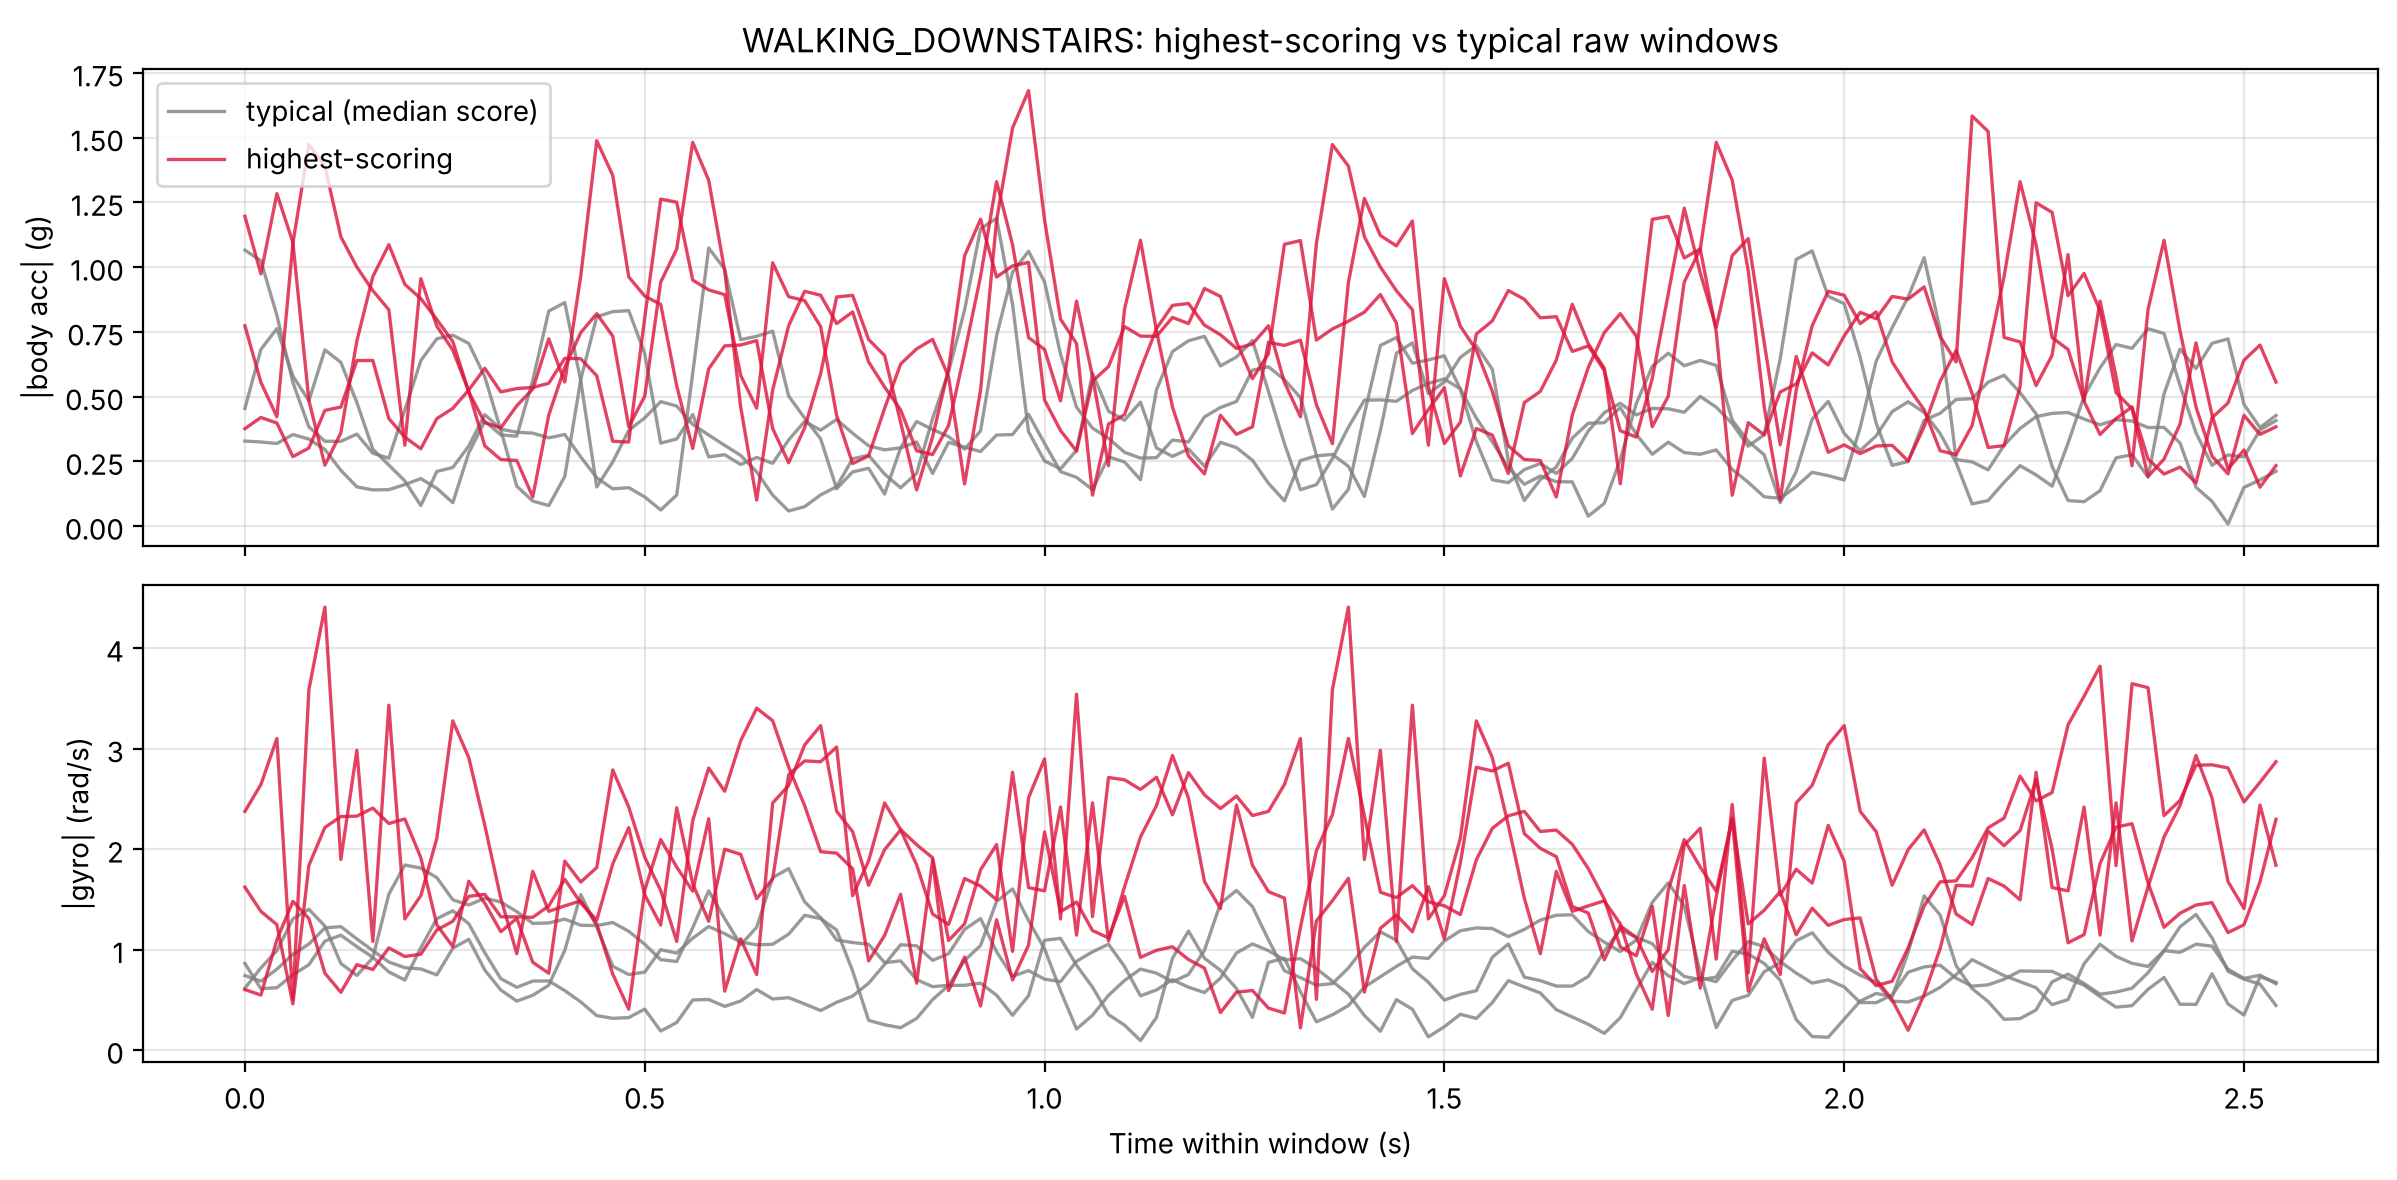

,subject_id,knn_score,acc_rms,acc_peak,gyro_rms,dominant_freq_hz,periodicity
3934,19,97.246,0.739,1.681,2.015,2.344,0.073
3935,19,96.170,0.734,1.482,2.102,2.344,0.099
3939,19,62.883,0.749,1.583,1.708,2.344,0.081
2673,15,19.001,0.512,1.066,0.725,3.906,0.086
6934,29,19.000,0.438,1.073,1.023,3.516,0.161
2338,14,18.988,0.415,1.188,0.895,3.516,0.094


In [23]:
EXAMPLE_ACTIVITY = "WALKING_DOWNSTAIRS"
ex = t6[t6["activity_name"] == EXAMPLE_ACTIVITY]
top_idx = ex.nlargest(3, "knn_score").index
typical_idx = (ex["knn_score"] - ex["knn_score"].median()).abs().nsmallest(3).index
tt = np.arange(128) / FS

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for idxs, color, lab in [(typical_idx, "grey", "typical (median score)"), (top_idx, "crimson", "highest-scoring")]:
    for j, i in enumerate(idxs):
        kw = dict(color=color, alpha=0.8, lw=1.2, label=lab if j == 0 else None)
        axes[0].plot(tt, acc_mag[i], **kw)
        axes[1].plot(tt, gyro_mag[i], **kw)
axes[0].set(ylabel="|body acc| (g)", title=f"{EXAMPLE_ACTIVITY}: highest-scoring vs typical raw windows")
axes[1].set(ylabel="|gyro| (rad/s)", xlabel="Time within window (s)")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(t6.loc[list(top_idx) + list(typical_idx),
               ["subject_id", "knn_score", "acc_rms", "acc_peak", "gyro_rms", "dominant_freq_hz", "periodicity"]]
        .round(3))

#### 6.6 Global vs restricted neighbourhoods
The same k-NN score computed (a) against all windows, (b) only against windows of the same activity, and (c) only against the same participant doing the same activity. None of these is ground truth; the question is how much the shortlist depends on the choice.

In [24]:
def knn_score_within(X, frame, group_cols, k):
    """k-NN distance computed only among windows that share the same group."""
    scores = np.full(len(X), np.nan)
    for _, idx in frame.groupby(group_cols).indices.items():
        kk = min(k, len(idx) - 1)
        d, _ = NearestNeighbors(n_neighbors=kk + 1).fit(X[idx]).kneighbors(X[idx])
        scores[idx] = d[:, kk]
    return scores


K_SUBJECT = 5   # subject-activity groups only hold 36-95 windows, so use a smaller neighbourhood
t6["score_within_activity"] = knn_score_within(X_train_scaled, t6, "activity_id", K)
t6["score_within_subject_activity"] = knn_score_within(X_train_scaled, t6, ["subject_id", "activity_id"], K_SUBJECT)
t6["local_distance"] = t6["score_within_activity"]   # used by the within-person deviation cell below

SCORES = {"global": "knn_score", "within activity": "score_within_activity",
          "within subject+activity": "score_within_subject_activity"}
flags = pd.DataFrame({name: t6[col] > np.percentile(t6[col], TOP_PCT) for name, col in SCORES.items()})


def jaccard(a, b):
    return (a & b).sum() / (a | b).sum()


names = list(SCORES)
print("Spearman rank correlation between scores:")
display(t6[list(SCORES.values())].set_axis(names, axis=1).corr(method="spearman").round(2))
print("Overlap of the top-5% shortlists (Jaccard):")
display(pd.DataFrame([[jaccard(flags[a], flags[b]) for b in names] for a in names],
                     index=names, columns=names).round(2))

Spearman rank correlation between scores:


,global,within activity,within subject+activity
global,1.00,1.00,0.94
within activity,1.00,1.00,0.94
within subject+activity,0.94,0.94,1.00


Overlap of the top-5% shortlists (Jaccard):


,global,within activity,within subject+activity
global,1.00,0.95,0.70
within activity,0.95,1.00,0.72
within subject+activity,0.70,0.72,1.00


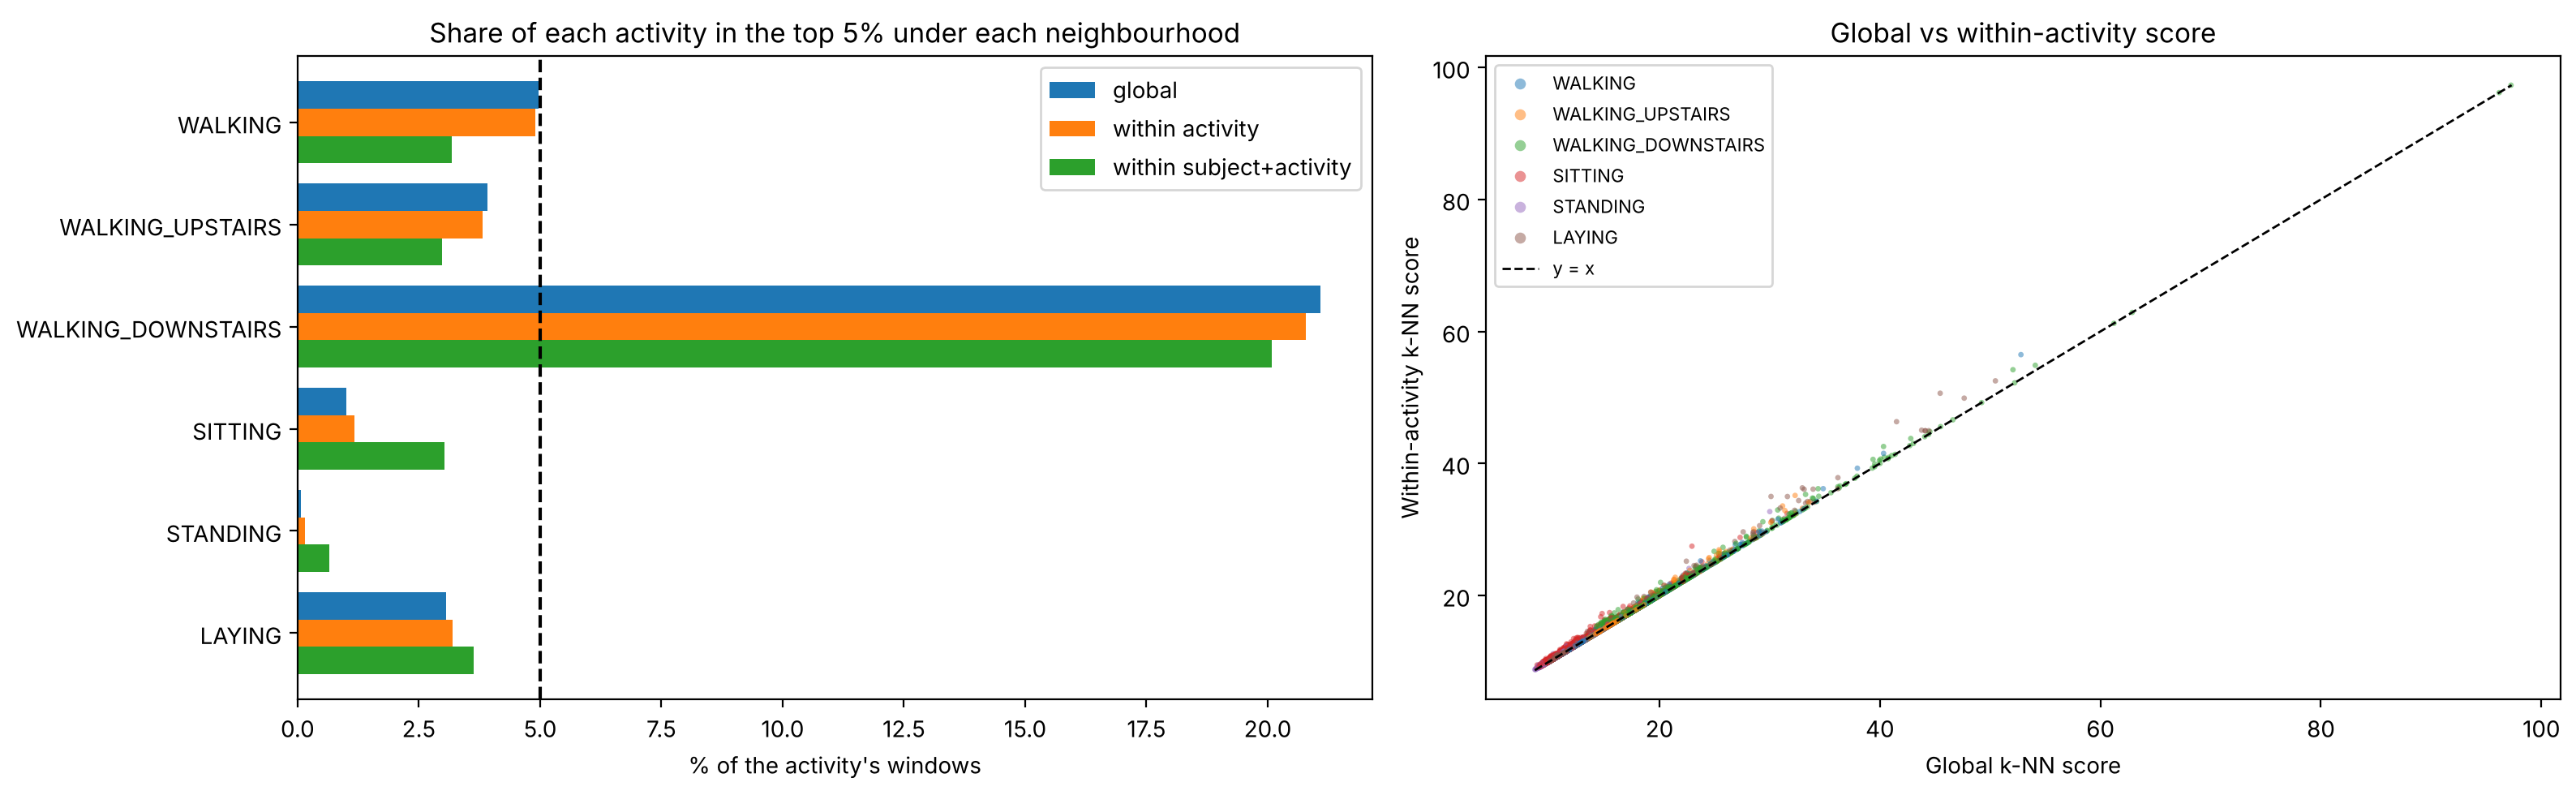

In [25]:
rate_by_act = flags.groupby(t6["activity_name"]).mean().reindex(ACTIVITY_ORDER) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rate_by_act.plot.barh(ax=axes[0], width=0.8)
axes[0].invert_yaxis()
axes[0].axvline(100 - TOP_PCT, color="black", ls="--")
axes[0].set(title="Share of each activity in the top 5% under each neighbourhood",
            xlabel="% of the activity's windows", ylabel="")
sns.scatterplot(data=t6, x="knn_score", y="score_within_activity", hue="activity_name", hue_order=ACTIVITY_ORDER,
                palette="tab10", s=6, alpha=0.5, linewidth=0, ax=axes[1])
lims = [t6["knn_score"].min(), t6["score_within_activity"].max()]
axes[1].plot(lims, lims, color="black", lw=1, ls="--", label="y = x")
axes[1].set(title="Global vs within-activity score", xlabel="Global k-NN score",
            ylabel="Within-activity k-NN score")
axes[1].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

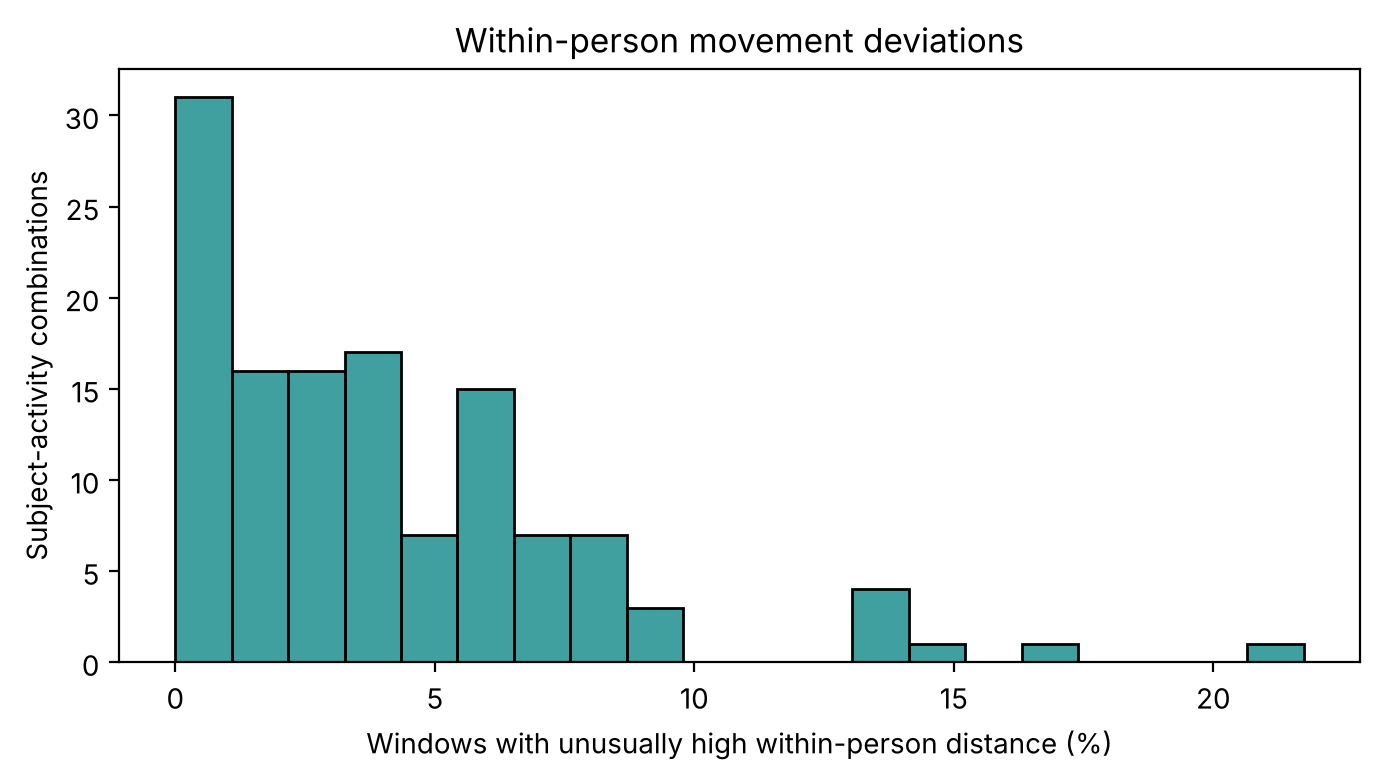

,subject_id,activity_id,n_windows,deviation_rate,activity_name
57,16,4,69,21.739130,SITTING
35,8,6,54,16.666667,LAYING
34,8,5,54,14.814815,STANDING
23,6,6,57,14.035088,LAYING
5,1,6,50,14.000000,LAYING
104,27,3,44,13.636364,WALKING_DOWNSTAIRS
87,23,4,68,13.235294,SITTING
41,11,6,57,8.771930,LAYING
33,8,4,46,8.695652,SITTING
78,22,1,46,8.695652,WALKING


Overlap of within-person deviations with the global shortlist (Jaccard): 0.14


In [26]:
# Within-person deviation: is a window unusual compared with the SAME person's other windows of that activity?
group_cols = ["subject_id", "activity_id"]
group_median = t6.groupby(group_cols)["local_distance"].transform("median")
group_mad = (t6["local_distance"] - group_median).abs().groupby([t6[c] for c in group_cols]).transform("median")
denominator = 1.4826 * group_mad

# near-zero MAD groups are left undefined rather than treating tiny differences as extreme
t6["local_robust_score"] = (t6["local_distance"] - group_median) / denominator.where(denominator > 1e-10)
ROBUST_Z = 3.5   # illustrative threshold, not a ground-truth label
t6["is_within_group_deviation"] = t6["local_robust_score"] > ROBUST_Z

comb_summary = (t6.groupby(group_cols)
                .agg(n_windows=("local_distance", "size"), deviation_rate=("is_within_group_deviation", "mean"))
                .reset_index())
comb_summary["deviation_rate"] *= 100
comb_summary["activity_name"] = comb_summary["activity_id"].map(ACTIVITY_NAMES)

plt.figure(figsize=(7, 4))
sns.histplot(comb_summary["deviation_rate"], bins=20, color="teal", edgecolor="black")
plt.xlabel("Windows with unusually high within-person distance (%)")
plt.ylabel("Subject-activity combinations")
plt.title("Within-person movement deviations")
plt.tight_layout()
plt.show()

display(comb_summary.sort_values("deviation_rate", ascending=False).head(10))
print(f"Overlap of within-person deviations with the global shortlist (Jaccard): "
      f"{jaccard(t6['is_within_group_deviation'], t6['is_high']):.2f}")

#### Task 6 findings (preliminary)
*These come from the baseline k-NN score (k = 15, top 5% = 368 windows). They mark what deserves further investigation; none of it is ground truth.*

1. **Walking downstairs dominates the shortlist.** 21% of its windows are high-scoring, 4.2× the overall rate (Holm p ≈ 1e-68). Standing (0.1%) and sitting (1%) are almost never flagged.
2. **A few participants account for most of it.** Subjects 19, 8, 23, 14 and 6 hold 74% of high-scoring windows. Each has 2.5–4× more than expected given their activity mix, and 65–85% of their downstairs windows are flagged. Subject 19 is distinctive beyond one activity (44% of walking windows also flagged). Subject 25's 33% laying rate is a separate case.
3. **High-scoring windows are not isolated points.** On average 45% of their nearest windows from *other* recordings are also high-scoring (5% expected at random). 61% have another high-scoring window two steps later in the same recording (3% for other windows). The top-ranked windows are consecutive windows from one subject-19 downstairs recording.
4. **Part of it comes from recording boundaries.** 52% of high-scoring windows lie within two windows of a recording's start or end (33% of all windows). For sitting the figure is 85%.
5. **Raw signals.** Dynamic high-scoring windows have higher intensity: body-acceleration RMS is 0.8–1.6 IQRs and rotation 1.5 IQRs above other windows of the same activity. Static high-scoring windows carry about 20 IQRs more body acceleration, meaning they contain real movement such as posture transitions rather than stillness.
6. **The choice of neighbourhood matters only partly.** Restricting neighbours to the same activity barely changes anything (ρ = 1.00, shortlist overlap 0.95), because global neighbours are already same-activity. Restricting to the same person and activity changes the shortlist more (overlap 0.70). Within-person deviations hardly overlap with the global shortlist (Jaccard 0.14), so they capture a different kind of unusualness.

**Open for RQ3:** points 2–3 suggest consistent individual differences in dynamic activities rather than one-off glitches. Point 4 suggests some static "anomalies" are labelling or transition artefacts.


## Research Questions

### Hand-off format: RQ1 & RQ2 → RQ3
RQ3 combines the outputs of RQ1 and RQ2 with participant IDs. To make that a drop-in step, **end your RQ section with one line** that builds your output with the helper below. Outputs are matched to windows by `(split, row)`, where `row` is the window's row position in `train_df` / `test_df`, so **keep the original row order**.

| From | Variable | How to build it | Columns |
|---|---|---|---|
| RQ1 | `rq1_output` | `make_rq1_output(labels, cluster_coarse=..., cluster_fine=...)` | `split, row, cluster` (+ optional extra levels named `cluster_*`) |
| RQ2 | `rq2_output` | `make_rq2_output({"iforest": scores, "lof": scores})` | `split, row, method, anomaly_score, is_anomaly` |

RQ2 scores must be **higher = more unusual** (negate sklearn's `score_samples` / `negative_outlier_factor_`). If `rq1_output` / `rq2_output` don't exist yet, RQ3 runs on clearly labelled dummy stand-ins.

In [27]:
def _check_keys(df, name):
    for split, part in df.groupby("split"):
        n = len(WINDOW_TABLE[split])
        assert part["row"].between(0, n - 1).all(), f"{name}: row out of range for split '{split}'"
    key = ["split", "row"] + (["method"] if "method" in df.columns else [])
    assert not df.duplicated(key).any(), f"{name}: duplicate rows for {key}"


def validate_rq1(df):
    assert {"split", "row", "cluster"} <= set(df.columns), "RQ1 output needs columns: split, row, cluster"
    _check_keys(df, "RQ1")
    assert df.filter(like="cluster").notna().all().all(), "RQ1 output has missing cluster labels"


def validate_rq2(df):
    need = {"split", "row", "method", "anomaly_score", "is_anomaly"}
    assert need <= set(df.columns), f"RQ2 output needs columns: {sorted(need)}"
    _check_keys(df, "RQ2")
    assert df["anomaly_score"].notna().all(), "RQ2 output has missing scores"
    assert df["is_anomaly"].dtype == bool, "RQ2 is_anomaly must be boolean"
    for method, rate in df.groupby("method")["is_anomaly"].mean().items():
        if not 0 < rate <= 0.2:
            print(f"Warning: method '{method}' flags {rate:.1%} of windows; RQ3 expects a short list")


def make_rq1_output(cluster, split="train", **other_levels):
    """RQ1 -> RQ3. `cluster`: one label per window of `split`, in train_df/test_df row order.
    Extra hierarchy levels are optional keyword arguments whose names start with 'cluster':
        rq1_output = make_rq1_output(kmeans6.labels_, cluster_coarse=kmeans2.labels_)"""
    n = len(WINDOW_TABLE[split])
    assert len(cluster) == n, f"expected {n} labels for split '{split}', got {len(cluster)}"
    out = pd.DataFrame({"split": split, "row": np.arange(n), "cluster": np.asarray(cluster)})
    for level, labels in other_levels.items():
        assert level.startswith("cluster"), "extra levels must be named cluster_<something>"
        assert len(labels) == n, f"{level}: expected {n} labels"
        out[level] = np.asarray(labels)
    validate_rq1(out)
    return out


def make_rq2_output(scores, split="train", flags=None, top_pct=95):
    """RQ2 -> RQ3. `scores`: dict {method_name: one score per window}, HIGHER = MORE UNUSUAL.
    `flags`: optional dict {method_name: boolean shortlist}; otherwise the top (100 - top_pct)% are flagged.
        rq2_output = make_rq2_output({"iforest": -iso.score_samples(X), "lof": -lof.negative_outlier_factor_})"""
    n = len(WINDOW_TABLE[split])
    parts = []
    for method, s in scores.items():
        s = np.asarray(s, float)
        assert len(s) == n, f"{method}: expected {n} scores for split '{split}', got {len(s)}"
        f = (np.asarray(flags[method], bool) if flags and method in flags
             else s > np.percentile(s, top_pct))
        parts.append(pd.DataFrame({"split": split, "row": np.arange(n), "method": method,
                                   "anomaly_score": s, "is_anomaly": f}))
    out = pd.concat(parts, ignore_index=True)
    validate_rq2(out)
    return out

### Research Question 1
**Members**: Atharva & Abrar

**Main Research Question:** Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?

**Methodology:**
1.	Perform unsupervised clustering (e.g., K-Means, GMM) on the 561-feature space.
2.  Analyze the resulting cluster structures (evaluate whether they form distinct groups or hierarchical sub-clusters)
3.  Compare unsupervized cluster assignment directuly against the hierarchical sub-clusters)
4.  Analyze divergence between machine-discovered structures vs human labeled classes

**Sub-Questions & Focus:**

1. Are the clusters truly 6 distinct groups mirroring the activity labels?
2. Can a geometric hierarchy be discovered within the space (e.g., are walking flat and walking upstairs grouped closer together than sitting and standing)?
3. How clearly do static postures separate from dynamic movements?

In [28]:
# Code for Question 1


# --- Hand-off to RQ3: keep this as the last line of RQ1 ---
# One cluster label per training window, in train_df row order. Extra hierarchy levels are optional.
# rq1_output = make_rq1_output(final_labels, split="train", cluster_coarse=coarse_labels)

### Research Question 2
**Members**: Youssef & Sushanth

**Main Research Question:** Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?

**Methodology:**
1.	Execute anomaly detection models (e.g., Isolation Forest, density-based outlier scoring) across the feature space.
2.	Map anomaly and outlier scores directly back against cluster boundaries and feature variance metrics.
3.	Analyze whether anomaly concentrations are isolated to specific activities or driven by high-variance physical regimes.

**Questions and Focus:**
1. Are high-intensity or dynamic activities (like walking downstairs) inherently more variable, causing them to trigger false anomaly flags?
2. Are anomalies uniformly distributed across all activities, or clustered heavily in specific movement transitions?
3. Do unusual scores reflect true physical irregularities or geometric boundary crowding?


In [29]:
# Code for Question 2


# --- Hand-off to RQ3: keep this as the last line of RQ2 ---
# One score per training window per method, HIGHER = MORE UNUSUAL (negate sklearn's score_samples).
# rq2_output = make_rq2_output({"iforest": -iso.score_samples(X_train_scaled),
#                               "lof": -lof.negative_outlier_factor_}, split="train")

### Research Question 3
**Members**: Muhatasim & Subhashini

**Main Research Question:** Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?

**Methodology:**
1.	Take the cluster assignments and anomaly shortlists generated in RQ1 and RQ2.
2.	Cross-tabulate these spatial outputs against the known subject ID metadata (the 30 participants).
3.	Evaluate whether outlier concentrations are driven by single individuals or shared across multiple subjects.
4.	Investigate how individual biometric walking styles interact with global unsupervised boundaries (leveraging the sequential nature of data per subject).

**Sub-questions and focus:**
1. Are the top anomalies dominated by a single eccentric participant (e.g., one subject's unique stride), or are they common instances experienced across many people?
2. Does the unsupervised space fracture by participant identity rather than activity class?
3. How does unmanaged inter-subject variance distort global anomaly detection?


#### RQ3.0 Inputs
Uses `rq1_output` / `rq2_output` if RQ1 and RQ2 have produced them; otherwise builds **dummy stand-ins** (K-Means on 10 PCs; default Isolation Forest and LOF) so every analysis and plot below already runs. The Task 6 k-NN score is always added as a reference method. Plot titles say when dummy inputs are in use.

In [30]:
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

FORCE_DUMMY = False   # True = ignore real RQ1/RQ2 outputs and run on dummy data (for testing)
RQ3_SPLIT = "train"
X_rq3 = X_train_scaled


def dummy_rq1_output(seed=42):
    """DUMMY stand-in for RQ1: K-Means on the first 10 principal components (6 and 2 clusters)."""
    pcs10 = PCA(n_components=10, random_state=seed).fit_transform(X_rq3)
    return make_rq1_output(KMeans(6, n_init=10, random_state=seed).fit_predict(pcs10), split=RQ3_SPLIT,
                           cluster_coarse=KMeans(2, n_init=10, random_state=seed).fit_predict(pcs10))


def dummy_rq2_output(seed=42):
    """DUMMY stand-in for RQ2: default Isolation Forest and LOF."""
    iso = IsolationForest(random_state=seed).fit(X_rq3)
    lof = LocalOutlierFactor(n_neighbors=20).fit(X_rq3)
    return make_rq2_output({"dummy_iforest": -iso.score_samples(X_rq3),
                            "dummy_lof": -lof.negative_outlier_factor_}, split=RQ3_SPLIT)


use_real_rq1 = "rq1_output" in globals() and not FORCE_DUMMY
use_real_rq2 = "rq2_output" in globals() and not FORCE_DUMMY
rq1_in = rq1_output if use_real_rq1 else dummy_rq1_output()
rq2_in = rq2_output if use_real_rq2 else dummy_rq2_output()
validate_rq1(rq1_in)
validate_rq2(rq2_in)

if "task6_knn" not in set(rq2_in["method"]):
    rq2_in = pd.concat([rq2_in, pd.DataFrame({"split": "train", "row": t6["row"], "method": "task6_knn",
                                              "anomaly_score": t6["knn_score"], "is_anomaly": t6["is_high"]})],
                       ignore_index=True)

TAG1 = "" if use_real_rq1 else "  [DUMMY RQ1 input]"
TAG2 = "" if use_real_rq2 else "  [DUMMY RQ2 input]"
window_cols = ["split", "row", "subject_id", "activity_id", "activity_name", "segment_id", "pos_in_segment"]
windows = WINDOW_TABLE[RQ3_SPLIT][window_cols]
rq3_clusters = windows.merge(rq1_in, on=["split", "row"], how="inner")
rq3_anom = windows.merge(rq2_in, on=["split", "row"], how="inner")
CLUSTER_LEVELS = [c for c in rq1_in.columns if c.startswith("cluster")]
METHODS = list(rq2_in["method"].unique())
PRIMARY_METHOD = METHODS[0]   # method used for the single-method plots below

print(f"RQ1 input: {'REAL' if use_real_rq1 else 'DUMMY'} | cluster levels: {CLUSTER_LEVELS}")
print(f"RQ2 input: {'REAL' if use_real_rq2 else 'DUMMY'} | methods: {METHODS} | primary: {PRIMARY_METHOD}")

RQ1 input: DUMMY | cluster levels: ['cluster', 'cluster_coarse']
RQ2 input: DUMMY | methods: ['dummy_iforest', 'dummy_lof', 'task6_knn'] | primary: dummy_iforest


#### RQ3.1 Are the top anomalies dominated by one participant?
For each method: the share of flagged windows from the top 1 and top 3 participants, compared with a null in which flags are shuffled **within each activity** (keeps activity rates, removes any link to who is moving). Enrichment = observed / expected flagged windows given the participant's activity mix.

,n_flagged,top_subject,top1_share,top1_null_95,p_top1,top3_share,top3_null_95,p_top3,subjects_flagged,subjects_2x_enriched
method,,,,,,,,,,
dummy_iforest,368,14,20.7%,8.4%,0.002,58.7%,22.0%,0.002,16,5
dummy_lof,368,19,10.9%,8.4%,0.002,28.0%,22.0%,0.002,21,1
task6_knn,368,19,17.4%,8.2%,0.002,48.1%,21.7%,0.002,20,5


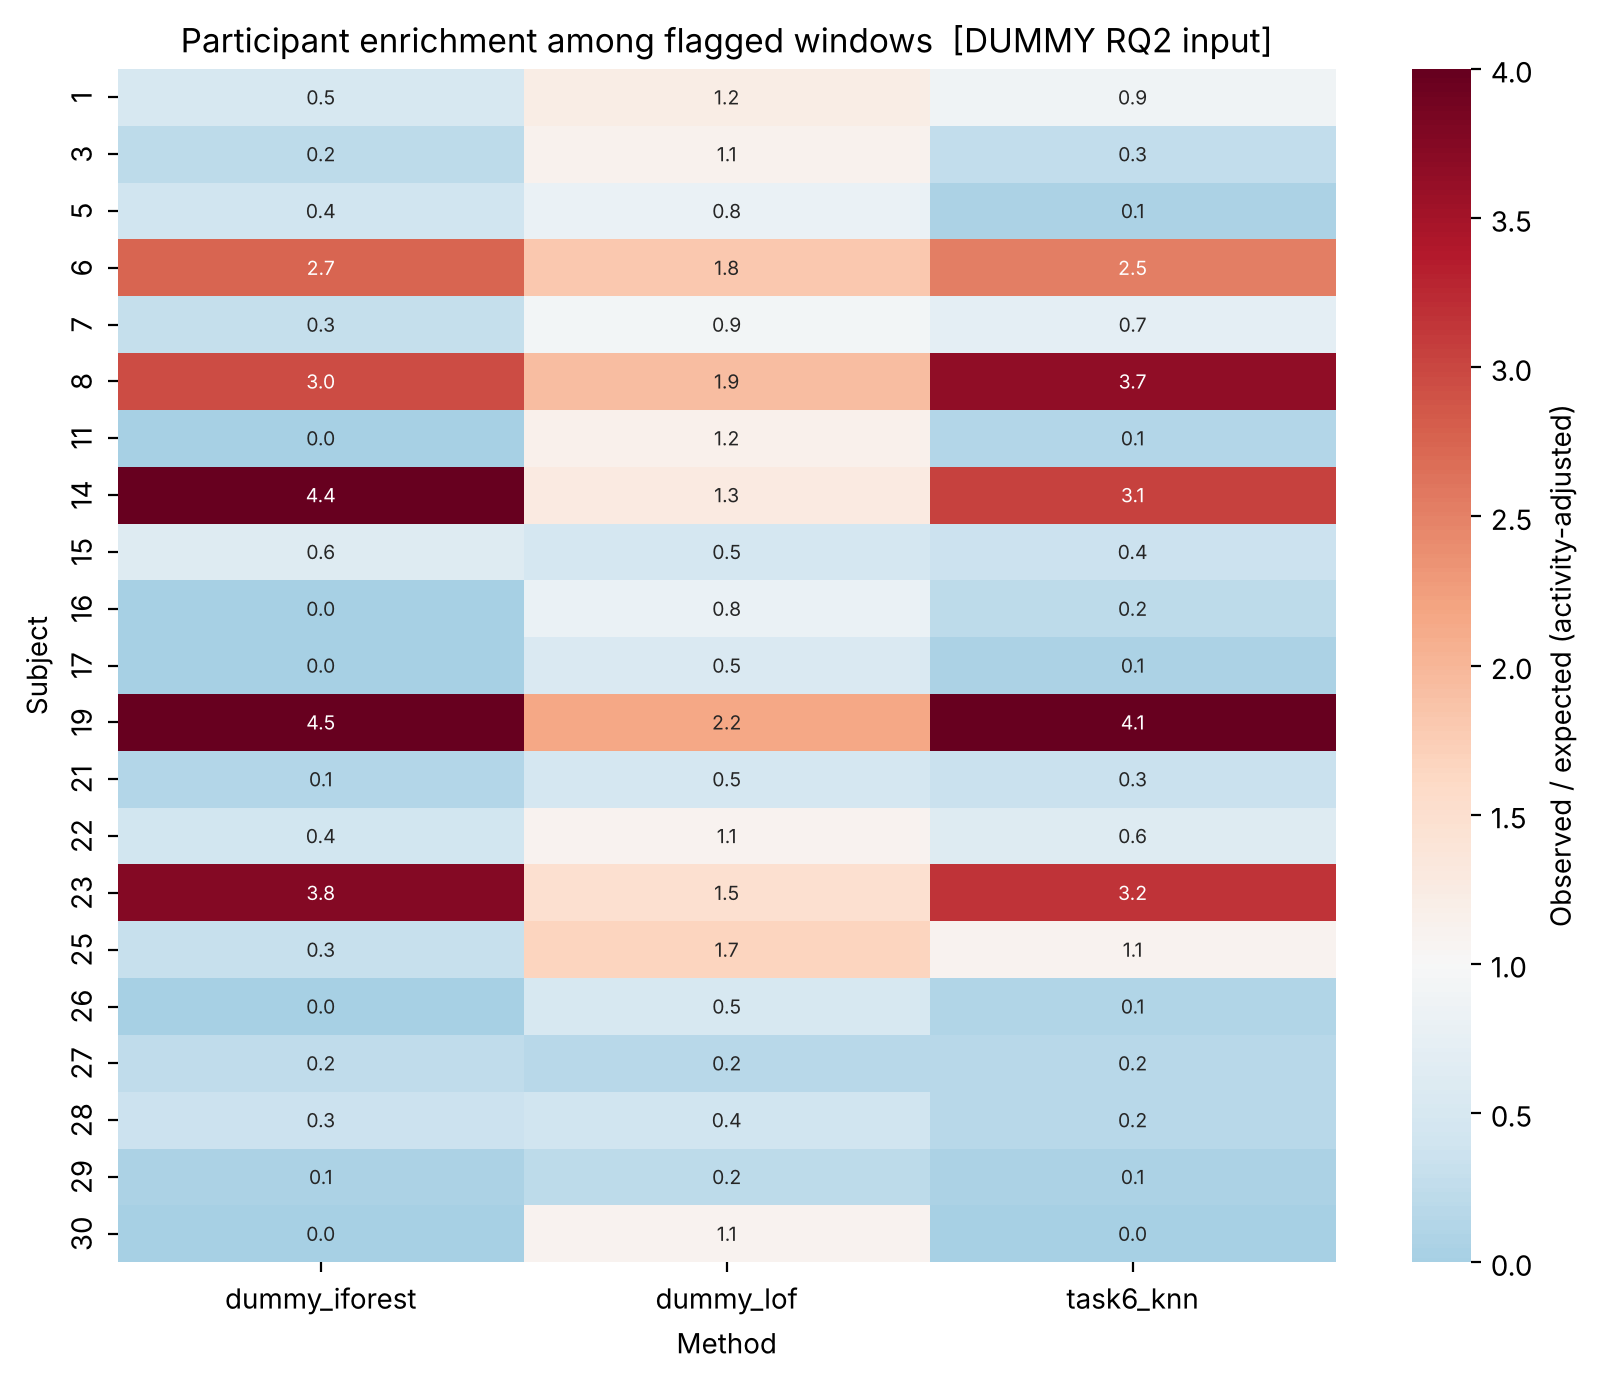

In [31]:
N_PERM = 500
rng = np.random.default_rng(0)


def top_shares(flags, subj_codes, n_subj):
    counts = np.sort(np.bincount(subj_codes, weights=flags, minlength=n_subj))[::-1]
    return counts[0] / counts.sum(), counts[:3].sum() / counts.sum()


rows, enrich = [], {}
for m, d in rq3_anom.groupby("method", sort=False):
    d = d.reset_index(drop=True)
    flags = d["is_anomaly"].to_numpy().astype(float)
    subj_codes, subj_ids = pd.factorize(d["subject_id"])
    expected = d.groupby("activity_id")["is_anomaly"].transform("mean")
    g = d.assign(expected=expected).groupby("subject_id").agg(observed=("is_anomaly", "sum"),
                                                              expected=("expected", "sum"))
    enrich[m] = g["observed"] / g["expected"]

    top1, top3 = top_shares(flags, subj_codes, len(subj_ids))
    groups = [np.flatnonzero(d["activity_id"].to_numpy() == a) for a in d["activity_id"].unique()]
    null = np.empty((N_PERM, 2))
    for b in range(N_PERM):
        f = flags.copy()
        for gi in groups:
            f[gi] = rng.permutation(f[gi])
        null[b] = top_shares(f, subj_codes, len(subj_ids))
    rows.append({"method": m, "n_flagged": int(flags.sum()), "top_subject": g["observed"].idxmax(),
                 "top1_share": top1, "top1_null_95": np.percentile(null[:, 0], 95),
                 "p_top1": (np.sum(null[:, 0] >= top1) + 1) / (N_PERM + 1),
                 "top3_share": top3, "top3_null_95": np.percentile(null[:, 1], 95),
                 "p_top3": (np.sum(null[:, 1] >= top3) + 1) / (N_PERM + 1),
                 "subjects_flagged": int((g["observed"] > 0).sum()),
                 "subjects_2x_enriched": int((enrich[m] >= 2).sum())})

sq1 = pd.DataFrame(rows).set_index("method")
display(sq1.style.format({c: "{:.1%}" for c in ["top1_share", "top1_null_95", "top3_share", "top3_null_95"]}
                         | {"p_top1": "{:.3f}", "p_top3": "{:.3f}"})
        .set_caption("Participant concentration of flagged windows" + TAG2))

enrich_df = pd.DataFrame(enrich)
plt.figure(figsize=(1.8 * len(enrich_df.columns) + 3, 7))
sns.heatmap(enrich_df, cmap="RdBu_r", center=1, vmin=0, vmax=4, annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Observed / expected (activity-adjusted)"})
plt.title("Participant enrichment among flagged windows" + TAG2)
plt.xlabel("Method")
plt.ylabel("Subject")
plt.tight_layout()
plt.show()

#### RQ3.2 Consistent individual differences or isolated departures?
Three complementary views:
1. **Who explains the score?** Within each activity, the share of score variation (ranks) explained by participant (η²). High η² = people differ consistently.
2. **Shifted person vs occasional spike.** For every participant-activity cell: the median within-activity score percentile (is the whole distribution shifted?) against the share of windows flagged. A *systematic* cell has a shifted median and an elevated flag rate; *isolated departures* are flags in a cell whose typical window is ordinary.
3. **Do flags persist in time?** P(window 2 steps later is flagged | this one is flagged), against the overall rate and the rate expected from the participant-activity cell alone.

In [32]:
from scipy.stats import kruskal

SYSTEMATIC_MEDIAN_PCT = 75   # the cell's typical window sits in the top quarter of its activity
ELEVATED_RATE = 2            # cell flag rate >= 2x the method's overall rate
LAG = 2                      # windows 2 steps apart share no samples

# (1) share of score variation explained by participant, per activity
rows = []
for (m, a), d in rq3_anom.groupby(["method", "activity_name"], sort=False):
    r = d["anomaly_score"].rank(pct=True)
    grp_mean = r.groupby(d["subject_id"]).transform("mean")
    eta2 = ((grp_mean - r.mean()) ** 2).sum() / ((r - r.mean()) ** 2).sum()
    p = kruskal(*[x.to_numpy() for _, x in r.groupby(d["subject_id"])]).pvalue
    rows.append({"method": m, "activity_name": a, "eta2_subject": eta2, "p": p})
eta = pd.DataFrame(rows)


# (2) participant-activity cells
def cell_profile(d):
    d = d.assign(pct=d.groupby("activity_id")["anomaly_score"].rank(pct=True) * 100)
    base = d["is_anomaly"].mean()
    cells = (d.groupby(["subject_id", "activity_name"])
             .agg(median_pct=("pct", "median"), flag_rate=("is_anomaly", "mean"),
                  n_flagged=("is_anomaly", "sum"), n=("is_anomaly", "size")).reset_index())
    cells["pattern"] = np.select(
        [(cells["median_pct"] >= SYSTEMATIC_MEDIAN_PCT) & (cells["flag_rate"] >= ELEVATED_RATE * base),
         cells["n_flagged"] > 0],
        ["systematic", "isolated departures"], default="no flags")
    return cells, base


# (3) temporal persistence
def persistence(d, lag=LAG):
    d = d.sort_values(["segment_id", "pos_in_segment"])
    later = d.groupby("segment_id")["is_anomaly"].shift(-lag)
    ok = later.notna()
    f, later = d.loc[ok, "is_anomaly"], later[ok].astype(bool)
    cell = d.groupby(["subject_id", "activity_id"])["is_anomaly"]
    loo_rate = ((cell.transform("sum") - 1) / (cell.transform("size") - 1))[ok]   # leave the window itself out
    return {"overall_rate": d["is_anomaly"].mean(), "expected_from_cell": loo_rate[f].mean(),
            "observed_P(flag | flag)": later[f].mean()}


share, persist, cells_by_method = {}, {}, {}
for m, d in rq3_anom.groupby("method", sort=False):
    cells, _ = cell_profile(d)
    cells_by_method[m] = cells
    share[m] = cells.groupby("pattern")["n_flagged"].sum() / cells["n_flagged"].sum()
    persist[m] = persistence(d)
share_df = pd.DataFrame(share).T.reindex(columns=["systematic", "isolated departures"]).fillna(0)
persist_df = pd.DataFrame(persist).T

display(share_df.style.format("{:.0%}").set_caption("Share of flagged windows by cell pattern" + TAG2))
display(persist_df.style.format("{:.1%}").set_caption(f"Temporal persistence at lag {LAG}" + TAG2))

pattern,systematic,isolated departures
dummy_iforest,80%,20%
dummy_lof,18%,82%
task6_knn,77%,23%


,overall_rate,expected_from_cell,observed_P(flag | flag)
dummy_iforest,5.0%,53.8%,64.1%
dummy_lof,5.0%,11.7%,18.4%
task6_knn,5.0%,44.8%,55.3%


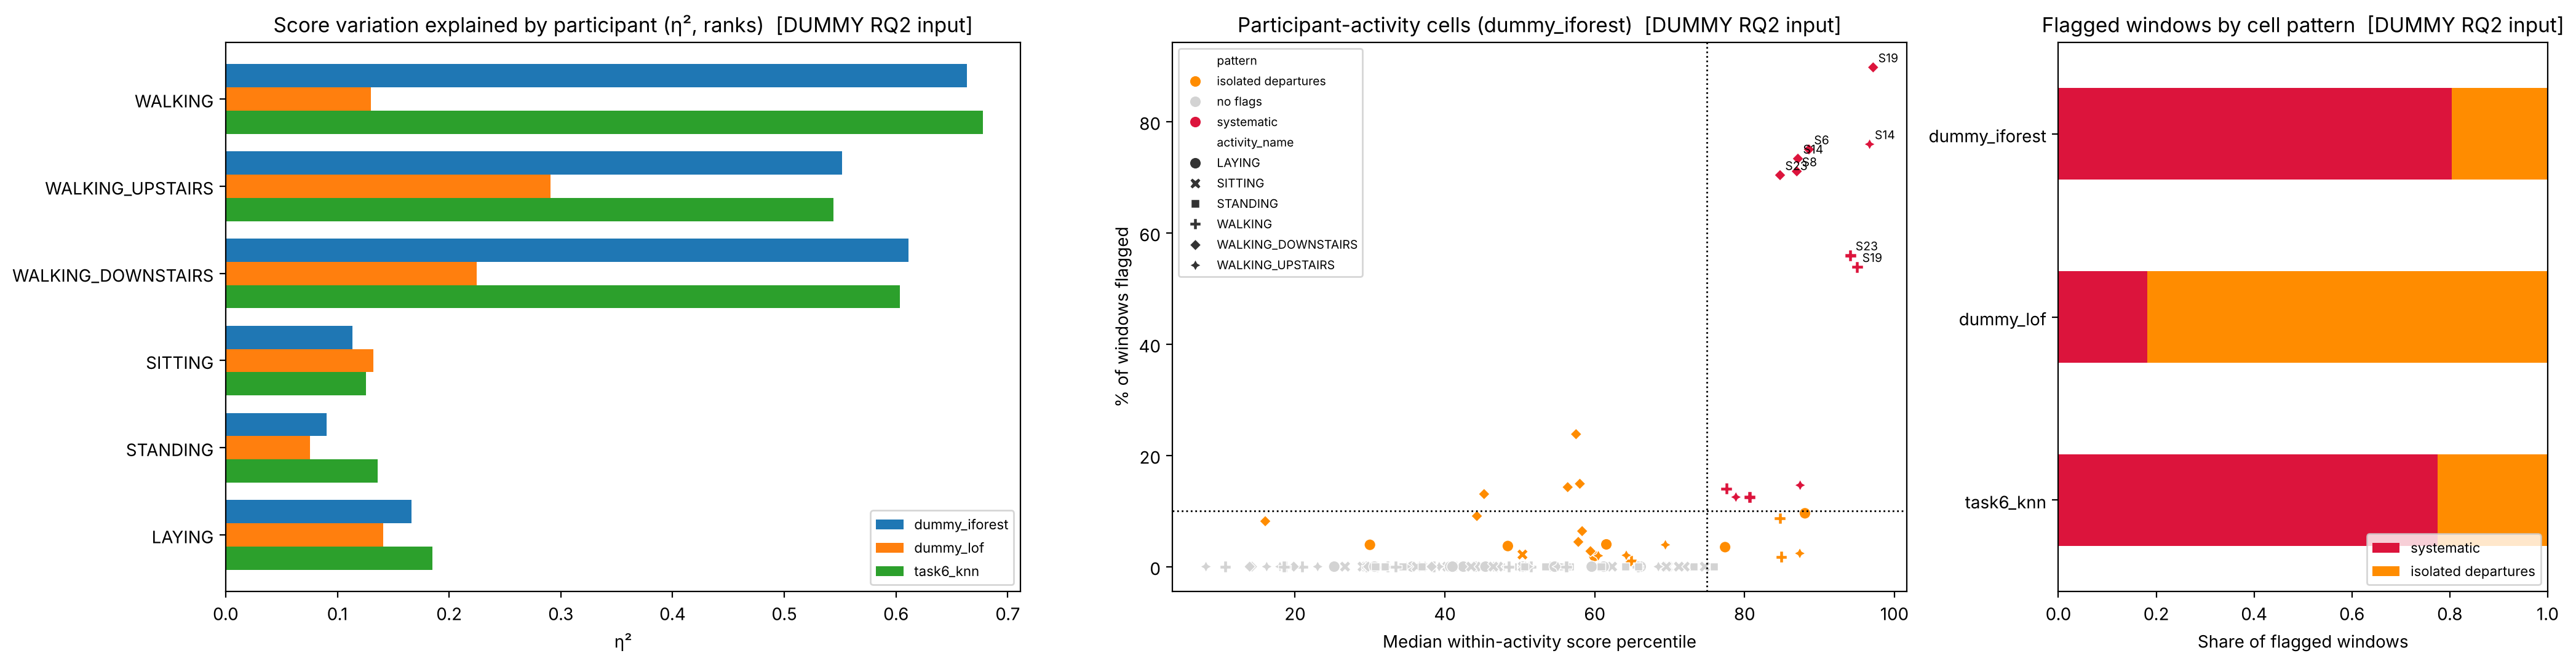

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1.3, 1.2, 0.8]})

eta_mat = eta.pivot(index="activity_name", columns="method", values="eta2_subject").reindex(ACTIVITY_ORDER)[METHODS]
eta_mat.plot.barh(ax=axes[0], width=0.8)
axes[0].invert_yaxis()
axes[0].set(title="Score variation explained by participant (η², ranks)" + TAG2, xlabel="η²", ylabel="")
axes[0].legend(fontsize=8)

cells = cells_by_method[PRIMARY_METHOD]
_, base = cell_profile(rq3_anom[rq3_anom["method"] == PRIMARY_METHOD])
palette = {"systematic": "crimson", "isolated departures": "darkorange", "no flags": "lightgrey"}
sns.scatterplot(data=cells, x="median_pct", y=cells["flag_rate"] * 100, hue="pattern", palette=palette,
                style="activity_name", s=45, ax=axes[1])
axes[1].axvline(SYSTEMATIC_MEDIAN_PCT, color="black", ls=":", lw=1)
axes[1].axhline(ELEVATED_RATE * base * 100, color="black", ls=":", lw=1)
for _, c in cells[cells["pattern"] == "systematic"].nlargest(8, "flag_rate").iterrows():
    axes[1].annotate(f"S{c.subject_id}", (c.median_pct, c.flag_rate * 100), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set(title=f"Participant-activity cells ({PRIMARY_METHOD})" + TAG2,
            xlabel="Median within-activity score percentile", ylabel="% of windows flagged")
axes[1].legend(fontsize=7, loc="upper left")

share_df.plot.barh(stacked=True, ax=axes[2], color=[palette["systematic"], palette["isolated departures"]])
axes[2].invert_yaxis()
axes[2].set(title="Flagged windows by cell pattern" + TAG2, xlabel="Share of flagged windows", xlim=(0, 1))
axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

#### RQ3.3 Does the unsupervised space fracture by participant rather than activity?
Adjusted mutual information (AMI, 0 = chance) between RQ1 clusters and activity vs participant, overall and within each activity. Independently of RQ1, the Task 6 neighbour table shows how often a window's nearest neighbours from *other recording segments* come from the same person, against what random neighbours within the activity would give.

,level,scope,AMI_activity,AMI_subject
0,cluster,all windows,0.561,0.057
1,cluster,LAYING,NaN,0.068
2,cluster,SITTING,NaN,0.054
3,cluster,STANDING,NaN,0.026
4,cluster,WALKING,NaN,0.238
5,cluster,WALKING_DOWNSTAIRS,NaN,0.235
6,cluster,WALKING_UPSTAIRS,NaN,0.164
7,cluster_coarse,all windows,0.543,0.003
8,cluster_coarse,LAYING,NaN,0.004
9,cluster_coarse,SITTING,NaN,0.000


,observed,random within activity,ratio
activity_name,,,
WALKING,84.5%,3.8%,22.2x
WALKING_UPSTAIRS,67.7%,4.1%,16.6x
WALKING_DOWNSTAIRS,53.2%,4.1%,13.1x
SITTING,10.7%,3.7%,2.9x
STANDING,12.0%,3.7%,3.2x
LAYING,28.1%,3.7%,7.6x


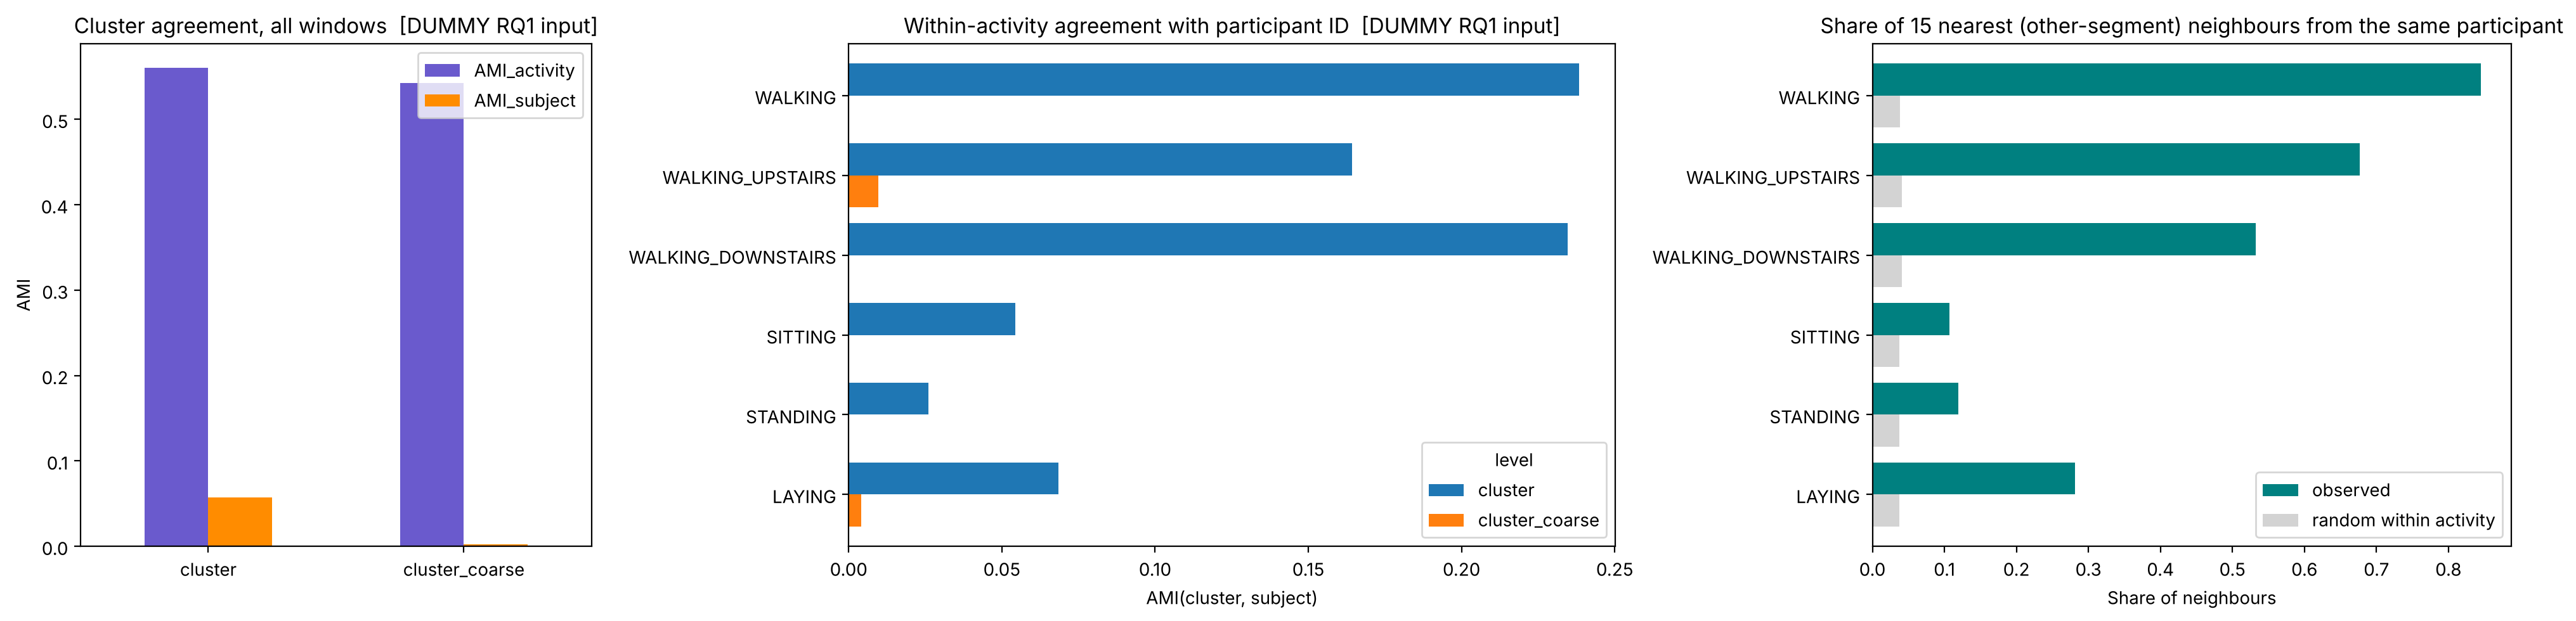

In [34]:
from sklearn.metrics import adjusted_mutual_info_score as ami

rows = []
for level in CLUSTER_LEVELS:
    rows.append({"level": level, "scope": "all windows",
                 "AMI_activity": ami(rq3_clusters["activity_id"], rq3_clusters[level]),
                 "AMI_subject": ami(rq3_clusters["subject_id"], rq3_clusters[level])})
    for a, d in rq3_clusters.groupby("activity_name"):
        if d[level].nunique() > 1:
            rows.append({"level": level, "scope": a, "AMI_activity": np.nan,
                         "AMI_subject": ami(d["subject_id"], d[level])})
sq3_ami = pd.DataFrame(rows)

# expected share if the K other-segment neighbours were drawn at random from the same activity
seg_n = t6.groupby("segment_id")["row"].transform("size")
t6["expected_same_subject"] = ((t6.groupby(["subject_id", "activity_id"])["row"].transform("size") - seg_n)
                               / (t6.groupby("activity_id")["row"].transform("size") - seg_n))
homophily = (t6.groupby("activity_name")[["frac_nbrs_same_subject", "expected_same_subject"]].mean()
             .reindex(ACTIVITY_ORDER).set_axis(["observed", "random within activity"], axis=1))
homophily["ratio"] = homophily["observed"] / homophily["random within activity"]

display(sq3_ami.round(3))
display(homophily.style.format({"observed": "{:.1%}", "random within activity": "{:.1%}", "ratio": "{:.1f}x"}))

fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [0.8, 1.2, 1]})
overall = sq3_ami[sq3_ami["scope"] == "all windows"].set_index("level")[["AMI_activity", "AMI_subject"]]
overall.plot.bar(ax=axes[0], rot=0, color=["slateblue", "darkorange"])
axes[0].set(title="Cluster agreement, all windows" + TAG1, ylabel="AMI", xlabel="")

within = sq3_ami[sq3_ami["scope"] != "all windows"].pivot(index="scope", columns="level", values="AMI_subject")
within.reindex([a for a in ACTIVITY_ORDER if a in within.index]).plot.barh(ax=axes[1], width=0.8)
axes[1].invert_yaxis()
axes[1].set(title="Within-activity agreement with participant ID" + TAG1, xlabel="AMI(cluster, subject)", ylabel="")

homophily[["observed", "random within activity"]].plot.barh(ax=axes[2], width=0.8, color=["teal", "lightgrey"])
axes[2].invert_yaxis()
axes[2].set(title=f"Share of {K} nearest (other-segment) neighbours from the same participant",
            xlabel="Share of neighbours", ylabel="")
plt.tight_layout()
plt.show()

#### RQ3.4 How does inter-subject variance distort global anomaly detection?
(a) Within each activity, the share of each feature's variance that lies between participants (η²). (b) Remove each participant's mean feature vector (uses subject IDs only, no activity labels), recompute the Task 6 k-NN score, and compare the shortlist before and after.

Spearman(raw, centred) = 0.98; shortlist overlap (Jaccard) = 0.88


,median_feature_eta2,share_features_eta2_over_0.5
activity_name,,
WALKING,0.62,63%
WALKING_UPSTAIRS,0.56,58%
WALKING_DOWNSTAIRS,0.47,48%
SITTING,0.07,1%
STANDING,0.10,3%
LAYING,0.10,3%


,global (raw),global (subject-centred)
top-1 participant share,0.174,0.174
top-3 participant share,0.481,0.462
participants >=2x enriched,5.000,5.000
max participant enrichment,4.074,4.007
rate: WALKING,0.050,0.049
rate: WALKING_UPSTAIRS,0.039,0.037
rate: WALKING_DOWNSTAIRS,0.211,0.199
rate: SITTING,0.010,0.016
rate: STANDING,0.001,0.002
rate: LAYING,0.031,0.034


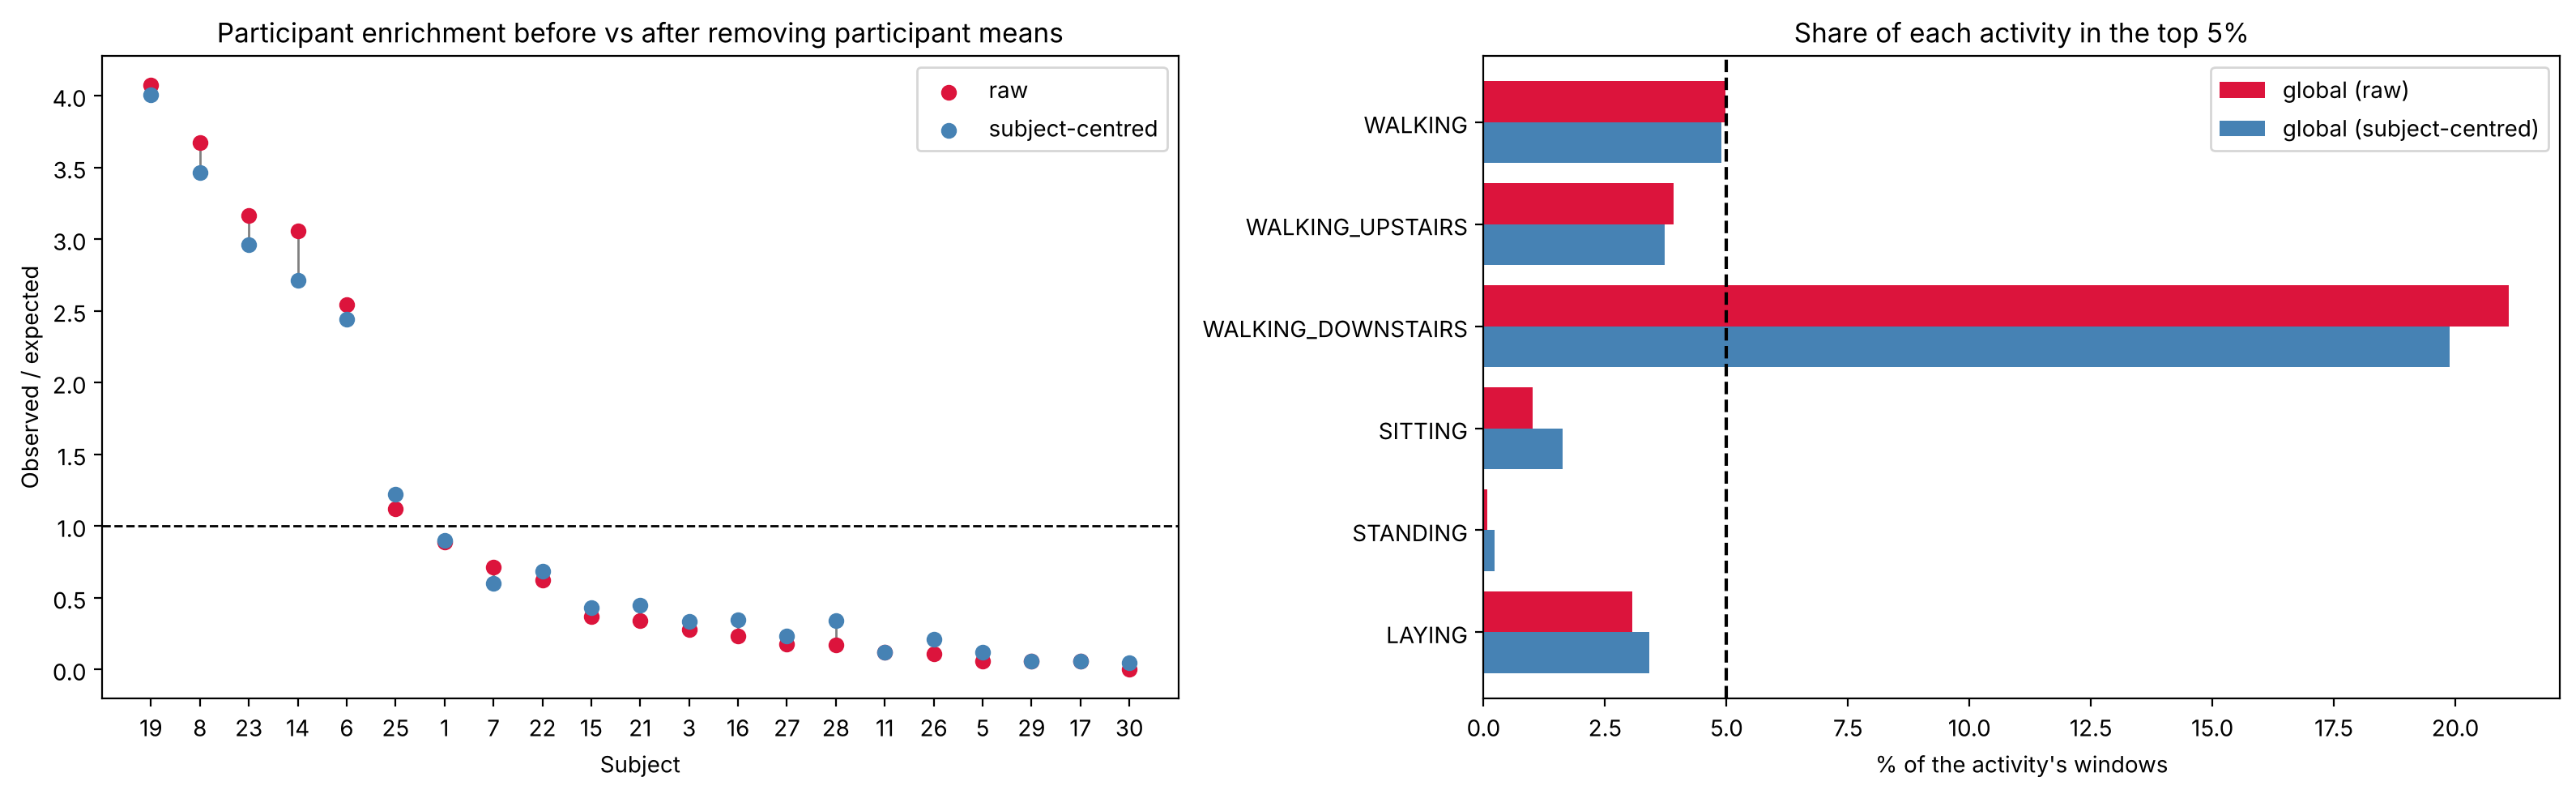

In [35]:
# (a) between-participant share of feature variance, per activity
subj_all = t6["subject_id"].to_numpy()
rows = []
for a, idx in t6.groupby("activity_name").indices.items():
    Xa = X_train_scaled[idx]
    grand = Xa.mean(axis=0)
    total = ((Xa - grand) ** 2).sum(axis=0)
    means = pd.DataFrame(Xa).groupby(subj_all[idx]).transform("mean").to_numpy()
    eta2 = ((means - grand) ** 2).sum(axis=0) / np.where(total > 0, total, np.nan)
    rows.append({"activity_name": a, "median_feature_eta2": np.nanmedian(eta2),
                 "share_features_eta2_over_0.5": np.nanmean(eta2 > 0.5)})
var_between = pd.DataFrame(rows).set_index("activity_name").reindex(ACTIVITY_ORDER)


# (b) subject-centred k-NN score
def subject_centre(X, subjects):
    """Subtract each participant's mean feature vector (over all their windows)."""
    return X - pd.DataFrame(X).groupby(subjects).transform("mean").to_numpy()


X_centred = subject_centre(X_train_scaled, subj_all)
d_c, _ = NearestNeighbors(n_neighbors=K + 1).fit(X_centred).kneighbors(X_centred)
t6["knn_score_centred"] = d_c[:, K]
t6["is_high_centred"] = t6["knn_score_centred"] > np.percentile(t6["knn_score_centred"], TOP_PCT)


def shortlist_profile(flag_col):
    codes, ids = pd.factorize(t6["subject_id"])
    top1, top3 = top_shares(t6[flag_col].to_numpy().astype(float), codes, len(ids))
    exp = t6.groupby("activity_id")[flag_col].transform("mean")
    enr = t6[flag_col].groupby(t6["subject_id"]).sum() / exp.groupby(t6["subject_id"]).sum()
    act_rate = t6.groupby("activity_name")[flag_col].mean()
    return {"top-1 participant share": top1, "top-3 participant share": top3,
            "participants >=2x enriched": int((enr >= 2).sum()),
            "max participant enrichment": enr.max(),
            **{f"rate: {a}": act_rate[a] for a in ACTIVITY_ORDER}}, enr


before, enr_before = shortlist_profile("is_high")
after, enr_after = shortlist_profile("is_high_centred")
distortion = pd.DataFrame({"global (raw)": before, "global (subject-centred)": after})
print(f"Spearman(raw, centred) = {t6[['knn_score', 'knn_score_centred']].corr(method='spearman').iloc[0, 1]:.2f}; "
      f"shortlist overlap (Jaccard) = {jaccard(t6['is_high'], t6['is_high_centred']):.2f}")
display(var_between.style.format({"median_feature_eta2": "{:.2f}", "share_features_eta2_over_0.5": "{:.0%}"}))
display(distortion.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = enr_before.sort_values(ascending=False).index
x = np.arange(len(order))
axes[0].scatter(x, enr_before[order], color="crimson", label="raw", zorder=3)
axes[0].scatter(x, enr_after[order], color="steelblue", label="subject-centred", zorder=3)
axes[0].vlines(x, enr_before[order], enr_after[order], color="grey", lw=1)
axes[0].axhline(1, color="black", ls="--", lw=1)
axes[0].set_xticks(x, order.astype(str))
axes[0].set(title="Participant enrichment before vs after removing participant means",
            xlabel="Subject", ylabel="Observed / expected")
axes[0].legend()

rates = distortion.loc[[f"rate: {a}" for a in ACTIVITY_ORDER]] * 100
rates.index = ACTIVITY_ORDER
rates.plot.barh(ax=axes[1], width=0.8, color=["crimson", "steelblue"])
axes[1].invert_yaxis()
axes[1].axvline(100 - TOP_PCT, color="black", ls="--")
axes[1].set(title="Share of each activity in the top 5%", xlabel="% of the activity's windows", ylabel="")
plt.tight_layout()
plt.show()

#### RQ3 findings
*Write once real RQ1/RQ2 outputs are in (the input banner above must say REAL for both). Where to read each answer:*
- **Dominated by one participant?** `sq1` table and enrichment heatmap: top-1/top-3 share vs the null, and how many participants are enriched.
- **Consistent differences vs isolated departures?** η² per activity, `share_df` (systematic vs isolated share of flags) and `persist_df` (persistence beyond the participant-activity rate means short episodes).
- **Does the space fracture by participant?** `sq3_ami` (AMI subject vs activity, overall and within activity) and the neighbour homophily table.
- **Distortion from inter-subject variance?** `var_between` and the before/after `distortion` table.